# CEG5302 Group 1 - Part 2: Task 3 (MW7) and Task 4 (RCM20)

This notebook contains **Part 2 only**: the template's Part 2 text and problem
classes, Task 3 (constrained NSGA-II on MW7, the teammate's cells unchanged) and
Task 4 (RCM20). It is not the group's complete submission; Part 1 and the final
packaging are added when the group notebook is assembled.

Run it top to bottom in a fresh kernel. It needs no other files and writes its
outputs next to itself (`task3_results/`, `results/`, `figures/`). The full
Task 4 study takes about 20 minutes.

In [1]:
import numpy as np

## Part 2. Constrained Multi-Objective Optimization

In this part, your task is to implement the parameter-less constraint handling technique in NSGA-II and use the constrained NSGA-II to solve constrained optimization problems.

### Introduction to a Constrained Optimization Problem: MW7

The MW test suite [3] is a constrained multi-objective optimization test suite proposed by Zhongwei Ma and Yong Wang. It is designed to evaluate the performance of constrained multi-objective optimization algorithms. MW7 is one of the test problems in the MW test suite. We have implemented the MW7() class and provided examples on how to use it below.

- Number of objectives: 2
- Number of decision variables: 15
- Number of constraints: 2

$$
\begin{aligned}
&\mathrm{minimize} \left\{
\begin{array}{l}
f_1(\mathbf{x})=g_3(\mathbf{x}) x_1 \\
f_2(\mathbf{x})=g_3(\mathbf{x}) \sqrt{1-\left(f_1(\mathbf{x}) / g_3(\mathbf{x})\right)^2}
\end{array}\:,\right. \\
&\mathrm{subject~to} \enspace c_1(\mathbf{x})=\left(1.2+0.4 \sin (4 l)^{16}\right)^2-(f_1(\mathbf{x}))^2-(f_2(\mathbf{x}))^2 \geq 0,\\
& \qquad \qquad c_2(\mathbf{x})=(f_1(\mathbf{x}))^2 + (f_2(\mathbf{x}))^2 - \left(1.15 - 0.2 \sin (4 l)^8\right)^2 \geq 0,\\
&\mathrm{where} \enspace g_3(\mathbf{x})=1+\sum_{i=2}^n 2\left(x_i+\left(x_{i-1}-0.5\right)^2-1\right)^2, \\
& \qquad \enspace l=\arctan \left(f_2(\mathbf{x}) / f_1(\mathbf{x})\right),\\
& \qquad \enspace 0 \leq x_i \leq 1, \enspace i=1,\ldots,n.
\end{aligned}
$$


[3] Ma, Z., & Wang, Y. (2019). Evolutionary constrained multiobjective optimization: Test suite construction and performance comparisons. IEEE Transactions on Evolutionary Computation, 23(6), 972-986.

In [2]:
class MW7():

    def __init__(self):
        self.name = 'MW7'
        self.n_obj = 2  # number of objectives
        self.n_var = 15  # number of decision variables
        self.n_con = 2  # number of constraints

        self.lower = np.zeros(self.n_var)
        self.upper = np.ones(self.n_var)

    def evaluate(self, x):
        pop_size = len(x)
        f = np.zeros((pop_size, self.n_obj))
        c = np.zeros((pop_size, self.n_con))

        g3 = 1 + 2.0 * np.sum((x[:, self.n_obj - 1:] +
                               (x[:, self.n_obj - 2:-1] - 0.5)**2 - 1.0)**2,
                              axis=1)

        f[:, 0] = g3 * x[:, 0]
        f[:, 1] = g3 * (1 - (f[:, 0] / g3)**2)**0.5

        with np.errstate(divide='ignore'):
            l = np.arctan(f[:, 1] / f[:, 0])

        c[:, 0] = (1.2 + 0.4 * (np.sin(4 * l))**16)**2 - f[:, 0]**2 - f[:, 1]**2
        c[:, 1] = f[:, 0]**2 + f[:, 1]**2 - (1.15 - 0.2 * (np.sin(4 * l))**8)**2
        c = np.where(c < 0, -c, 0)  # the degree of constraint violation of x at each constraint

        return f, c

In [3]:
# Create an instance of MW7
prob = MW7()
print(f"Problem = {prob.name}")
print(f"Number of objectives = {prob.n_obj}")
print(f"Number of variables = {prob.n_var}")
print(f"Number of constraints = {prob.n_con}")
print(f"Lower bounds = {prob.lower}")
print(f"Upper bounds = {prob.upper}")

Problem = MW7
Number of objectives = 2
Number of variables = 15
Number of constraints = 2
Lower bounds = [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Upper bounds = [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [4]:
# Initialize a population with 1 solution and evaluate it
pop_size = 1
x = prob.lower + (prob.upper - prob.lower) * np.random.rand(
    pop_size, prob.n_var)
print("x = ", x)

f, c = prob.evaluate(x)
print(f"f(x) = {f}")
print(f"c(x) = {c}")
print(f"CV(x) = {np.sum(c, axis=1, keepdims=True)}")  # Constraint Violation

x =  [[0.78420852 0.30686144 0.10160561 0.87161101 0.50904296 0.41132592
  0.10575988 0.39510772 0.87610406 0.74800974 0.06405718 0.87646197
  0.85669926 0.53714882 0.98397558]]
f(x) = [[6.24685333 4.94276211]]
c(x) = [[62.01407132  0.        ]]
CV(x) = [[62.01407132]]


In [5]:
# Initialize a population with 2 solution and evaluate them
pop_size = 2
x = prob.lower + (prob.upper - prob.lower) * np.random.rand(
    pop_size, prob.n_var)
print("x = ", x)

f, c = prob.evaluate(x)
print(f"f(x) = {f}")
print(f"c(x) = {c}")
print(f"CV(x) = {np.sum(c, axis=1, keepdims=True)}")

x =  [[0.28018322 0.92888199 0.21098648 0.27416328 0.58774402 0.2397566
  0.23159587 0.63084691 0.74317618 0.06794557 0.49539532 0.24610046
  0.92259646 0.38504095 0.23386803]
 [0.7475807  0.89810128 0.65493149 0.14154536 0.42629623 0.34051573
  0.29754573 0.32379117 0.2952368  0.20036826 0.2066331  0.04382547
  0.67586334 0.41528931 0.91540269]]
f(x) = [[2.69064237 9.21851381]
 [7.96457301 7.07594287]]
c(x) = [[ 90.57241064   0.        ]
 [112.06339072   0.        ]]
CV(x) = [[ 90.57241064]
 [112.06339072]]


### TODO: Implement Constrained NSGA-II and Solve MW7 (30 marks)
Your task is to **implement the parameter-less constraint handling technique in NSGA-II and use the constrained NSGA-II to solve the MW7 problem**.

You can refer to the example figures below for reference. The left figure (from [3]) displays the true Pareto front (represented by red points), the unconstrained Pareto front (represented by the blue line), and the feasible region (represented by the gray region). The right figure displays the final population obtained by NSGA-II. Your expected solutions should be similar to the gray circles in the right figure.

<div style="display: flex;">
    <img src="PF_MW7.png" alt="PF of MW7" style="width: 40%;">
    <img src="NSGA2_MW7.png" alt="NSGA2 on MW7" style="width: 40%;">
</div>

Note that sometimes the solutions obtained by NSGA-II may not cover all segments of the Pareto front (as shown below). **What are the possible reasons? Please share your thoughts in your report.**

<div style="display: flex;">
    <img src="NSGA2_MW7_2.png" alt="NSGA2 on MW7 2" style="width: 40%;">
    <img src="NSGA2_MW7_3.png" alt="NSGA2 on MW7 3" style="width: 40%;">
</div>

# Task 3 — Constrained NSGA-II on MW7

Baseline: **N=100, 500 evolutionary updates, pc=0.8, pm=0.05,
eta_c=eta_m=20; seeds 0–4**. Each seed uses 50,100 search evaluations, including
initialization. This starting configuration is not claimed to be optimal.
A separate N=20, 20-update smoke run checks mechanics before the baseline runs.


In [6]:
import argparse
import base64
import csv
import hashlib
import json
import os
import platform
import time
from pathlib import Path

import numpy as np
import matplotlib
try:
    from IPython import get_ipython
    TASK3_IN_NOTEBOOK = getattr(get_ipython(), "kernel", None) is not None
except ImportError:
    TASK3_IN_NOTEBOOK = False
matplotlib.use("module://matplotlib_inline.backend_inline" if TASK3_IN_NOTEBOOK else "Agg")
import matplotlib.pyplot as plt
if TASK3_IN_NOTEBOOK:
    from IPython.display import Markdown, Image, display

TASK3_MODE = os.environ.get("TASK3_MODE", "run").strip().lower()
TASK3_OUTPUT_DIR = Path(os.environ.get("TASK3_OUTPUT_DIR", "task3_results/baseline-v1"))
if not TASK3_IN_NOTEBOOK:
    task3_parser = argparse.ArgumentParser(description="Run MW7 experiments in Python, then export results for Notebook assembly.")
    task3_parser.add_argument("--mode", choices=("run", "load", "check"), default=TASK3_MODE)
    task3_parser.add_argument("--output-dir", type=Path, default=TASK3_OUTPUT_DIR)
    task3_args = task3_parser.parse_args()
    TASK3_MODE, TASK3_OUTPUT_DIR = task3_args.mode, task3_args.output_dir
if TASK3_MODE not in {"run", "load", "check"}:
    raise ValueError("TASK3_MODE must be run, load, or check")
TASK3_SOURCE_PATH = Path(__file__).resolve() if not TASK3_IN_NOTEBOOK else Path("task3/task3_mw7.py")
TASK3_SOURCE_SHA256 = (hashlib.sha256(TASK3_SOURCE_PATH.read_bytes()).hexdigest()
                      if TASK3_SOURCE_PATH.exists() else None)
TASK3_CAPTURED_OUTPUTS = {}
TASK3_ALGORITHM_VERSION = "task3-cnsga2-v1"
TASK3_BASELINE = dict(pop_size=100, max_gen=500, pc=0.8, pm=0.05,
                      eta_c=20.0, eta_m=20.0, cv_tol=1e-12)
TASK3_SEEDS = (0, 1, 2, 3, 4)
TASK3_SMOKE = dict(TASK3_BASELINE, pop_size=20, max_gen=20)
TASK3_SMOKE_SEED = 2026

def task3_emit_text(tag, text):
    print(text, flush=True)
    TASK3_CAPTURED_OUTPUTS.setdefault(tag, []).append(
        dict(output_type="stream", name="stdout", text=text + "\n"))


def task3_emit_markdown(tag, text):
    if TASK3_IN_NOTEBOOK:
        display(Markdown(text))
    else:
        print(text, flush=True)
    TASK3_CAPTURED_OUTPUTS.setdefault(tag, []).append(
        dict(output_type="display_data", metadata={},
             data={"text/markdown": text, "text/plain": text}))


def task3_emit_figure(tag, path):
    png = path.read_bytes()
    if TASK3_IN_NOTEBOOK:
        display(Image(data=png))
    else:
        print("Saved figure:", path, flush=True)
    TASK3_CAPTURED_OUTPUTS.setdefault(tag, []).append(
        dict(output_type="display_data", metadata={},
             data={"image/png": base64.b64encode(png).decode("ascii"),
                   "text/plain": f"Generated figure: {path.name}"}))


task3_emit_text("task3-config", f"Mode: {TASK3_MODE} | Results: {TASK3_OUTPUT_DIR.resolve()}")
task3_emit_text("task3-config", f"Python: {platform.python_version()} NumPy: {np.__version__} Matplotlib: {matplotlib.__version__}")


Mode: run | Results: task3_results/baseline-v1


Python: 3.13.9 NumPy: 2.3.5 Matplotlib: 3.10.6


## 1. Supplied MW7 — unchanged

MW7 has 15 variables in [0,1], two minimization objectives and two constraints.
Original constraint expressions are feasible when nonnegative. The supplied
evaluator already converts them to violation magnitudes: it returns F[N,2] and
nonnegative C[N,2]. Calculate CV=C.sum(axis=1), without negating C again.
Numerically, CV <= 1e-12 is treated as feasible; strict CV == 0 counts are also
reported. This tolerance is not a penalty coefficient. Violations are summed
without rescaling, following the supplied example.


*(Task 3's MW7 cell is omitted: it is identical to the template's MW7 class above.)*

## 2. Constrained NSGA-II

The parameter-less constraint rules are: (1) feasible beats infeasible;
(2) between infeasible candidates, lower total CV wins; (3) between feasible
candidates, ordinary Pareto dominance applies. Equal-CV infeasible candidates
do not constraint-dominate each other. Within a front, normalized objective
crowding breaks ties; exact rank/distance ties are randomized with the run seed.
Both mating selection and environmental selection use these same rules.


In [7]:
class CNSGA2:
    """Constraint-domination NSGA-II for minimization."""

    def __init__(self, pop_size=100, pc=0.8, pm=0.05,
                 eta_c=20.0, eta_m=20.0, cv_tol=1e-12, seed=0):
        if not isinstance(pop_size, (int, np.integer)) or pop_size < 2 or pop_size % 2:
            raise ValueError("pop_size must be an even integer >= 2")
        if not (0 <= pc <= 1 and 0 <= pm <= 1):
            raise ValueError("pc and pm must be in [0,1]")
        if not (np.isfinite(eta_c) and np.isfinite(eta_m) and eta_c > 0 and eta_m > 0):
            raise ValueError("distribution indices must be finite and positive")
        if not np.isfinite(cv_tol) or cv_tol < 0:
            raise ValueError("cv_tol must be finite and nonnegative")
        self.pop_size = int(pop_size)
        self.pc, self.pm = float(pc), float(pm)
        self.eta_c, self.eta_m = float(eta_c), float(eta_m)
        self.cv_tol, self.seed = float(cv_tol), int(seed)
        self.rng = np.random.default_rng(self.seed)
        self.n_evals = 0

    def initialize(self, prob):
        lower, upper = np.asarray(prob.lower), np.asarray(prob.upper)
        if (lower.shape != (prob.n_var,) or upper.shape != lower.shape
                or not np.isfinite(lower).all() or not np.isfinite(upper).all()
                or not np.all(upper > lower)):
            raise ValueError("Expected finite bounds with upper > lower")
        return self.rng.uniform(lower, upper, (self.pop_size, prob.n_var))

    @staticmethod
    def _pareto_dominance(f):
        # Entry (i,j): candidate i dominates candidate j.
        return (np.all(f[:, None, :] <= f[None, :, :], axis=2)
                & np.any(f[:, None, :] < f[None, :, :], axis=2))

    def _constraint_dominance(self, f, cv):
        feasible = cv <= self.cv_tol
        both_feasible = feasible[:, None] & feasible[None, :]
        both_infeasible = ~feasible[:, None] & ~feasible[None, :]
        return ((both_feasible & self._pareto_dominance(f))
                | (feasible[:, None] & ~feasible[None, :])
                | (both_infeasible & (cv[:, None] < cv[None, :])))

    @staticmethod
    def _sort_fronts(dominates):
        rank = np.zeros(len(dominates), dtype=int)
        remaining = dominates.sum(axis=0).astype(int)
        fronts, level = [], 1
        while np.any(rank == 0):
            front = np.flatnonzero((rank == 0) & (remaining == 0))
            if front.size == 0:
                raise RuntimeError("Dominance relation contains a cycle")
            fronts.append(front)
            rank[front] = level
            remaining -= dominates[front].sum(axis=0)
            level += 1
        return rank, fronts

    @staticmethod
    def _crowding_distance(f, fronts):
        distance = np.zeros(len(f), dtype=float)
        for front in fronts:
            if len(front) <= 2:
                distance[front] = np.inf
                continue
            for objective in range(f.shape[1]):
                order = front[np.argsort(f[front, objective], kind="stable")]
                span = f[order[-1], objective] - f[order[0], objective]
                if span == 0:
                    continue
                distance[order[0]] = distance[order[-1]] = np.inf
                distance[order[1:-1]] += (f[order[2:], objective] - f[order[:-2], objective]) / span
        return distance

    def fitness_assignment(self, f, cv):
        f, cv = np.asarray(f, dtype=float), np.asarray(cv, dtype=float)
        if (f.ndim != 2 or len(f) == 0 or f.shape[1] == 0
                or cv.shape != (len(f),) or not np.isfinite(f).all()
                or not np.isfinite(cv).all() or np.any(cv < 0)):
            raise ValueError("Expected finite F[N,M] and nonnegative CV[N]")
        rank, fronts = self._sort_fronts(self._constraint_dominance(f, cv))
        return rank, self._crowding_distance(f, fronts)

    def tournament_selection(self, population_x, rank, crowding_dist):
        mating_pool = np.empty_like(population_x)
        for i in range(self.pop_size):
            a, b = self.rng.choice(len(population_x), 2, replace=False)
            if rank[a] != rank[b]:
                winner = a if rank[a] < rank[b] else b
            elif crowding_dist[a] != crowding_dist[b]:
                winner = a if crowding_dist[a] > crowding_dist[b] else b
            else:
                winner = int(self.rng.choice([a, b]))
            mating_pool[i] = population_x[winner]
        return mating_pool

    def crossover(self, parents, prob):
        children = parents.copy()
        for i in range(0, self.pop_size, 2):
            if self.rng.random() <= self.pc:
                p1, p2 = parents[i], parents[i + 1]
                u = self.rng.random(prob.n_var)
                beta = np.where(u <= 0.5,
                                (2 * u) ** (1 / (self.eta_c + 1)),
                                (1 / (2 * (1 - u))) ** (1 / (self.eta_c + 1)))
                children[i] = np.clip(
                    0.5 * ((1 + beta) * p1 + (1 - beta) * p2), prob.lower, prob.upper)
                children[i + 1] = np.clip(
                    0.5 * ((1 - beta) * p1 + (1 + beta) * p2), prob.lower, prob.upper)
        return children

    def mutation(self, offspring, prob):
        children = offspring.copy()
        for i in range(self.pop_size):
            for j in range(prob.n_var):
                if self.rng.random() <= self.pm:
                    value = children[i, j]
                    lower, upper = prob.lower[j], prob.upper[j]
                    delta1 = (value - lower) / (upper - lower)
                    delta2 = (upper - value) / (upper - lower)
                    u, power = self.rng.random(), 1 / (self.eta_m + 1)
                    if u < 0.5:
                        v = 2 * u + (1 - 2 * u) * (1 - delta1) ** (self.eta_m + 1)
                        delta = v ** power - 1
                    else:
                        v = 2 * (1 - u) + 2 * (u - 0.5) * (1 - delta2) ** (self.eta_m + 1)
                        delta = 1 - v ** power
                    children[i, j] = np.clip(value + delta * (upper - lower), lower, upper)
        return children

    def _evaluate(self, prob, x):
        if (x.shape != (self.pop_size, prob.n_var) or not np.isfinite(x).all()
                or np.any(x < prob.lower) or np.any(x > prob.upper)):
            raise ValueError("Invalid decision vectors or variable bounds")
        f, c = prob.evaluate(x)
        f, c = np.asarray(f, dtype=float), np.asarray(c, dtype=float)
        if (f.shape != (len(x), prob.n_obj) or c.shape != (len(x), prob.n_con)
                or not np.isfinite(f).all() or not np.isfinite(c).all() or np.any(c < 0)):
            raise ValueError("Invalid objectives or constraint violation magnitudes")
        self.n_evals += len(x)
        return f, c, c.sum(axis=1)

    def environmental_selection(self, x, f, c, offspring_x, offspring_f, offspring_c):
        combined_x = np.vstack((x, offspring_x))
        combined_f = np.vstack((f, offspring_f))
        combined_c = np.vstack((c, offspring_c))
        combined_cv = combined_c.sum(axis=1)
        rank, distance = self.fitness_assignment(combined_f, combined_cv)
        tie_break = self.rng.random(len(combined_x))
        selected = np.lexsort((tie_break, -distance, rank))[:self.pop_size]
        return (combined_x[selected], combined_f[selected],
                combined_c[selected], combined_cv[selected])

    def feasible_nd_mask(self, f, cv):
        indices = np.flatnonzero(cv <= self.cv_tol)
        selected = np.zeros(len(f), dtype=bool)
        if len(indices):
            dominated = np.any(self._pareto_dominance(f[indices]), axis=0)
            selected[indices[~dominated]] = True
        return selected

    def _record(self, history, generation, f, cv):
        history.append(dict(generation=generation, n_evals=self.n_evals,
                            feasible_ratio=float(np.mean(cv <= self.cv_tol)),
                            strict_feasible_ratio=float(np.mean(cv == 0)),
                            min_cv=float(cv.min()), mean_cv=float(cv.mean()),
                            max_cv=float(cv.max()),
                            feasible_nd_count=int(self.feasible_nd_mask(f, cv).sum())))

    def run(self, prob, max_gen=500, progress_every=100):
        if not isinstance(max_gen, (int, np.integer)) or max_gen < 0:
            raise ValueError("max_gen must be a nonnegative integer")
        self.rng = np.random.default_rng(self.seed)
        self.n_evals = 0
        started = time.perf_counter()
        x = self.initialize(prob)
        f, c, cv = self._evaluate(prob, x)
        history = []
        self._record(history, 0, f, cv)
        for generation in range(1, max_gen + 1):
            rank, distance = self.fitness_assignment(f, cv)
            parents = self.tournament_selection(x, rank, distance)
            offspring_x = self.mutation(self.crossover(parents, prob), prob)
            offspring_f, offspring_c, _ = self._evaluate(prob, offspring_x)
            x, f, c, cv = self.environmental_selection(x, f, c, offspring_x, offspring_f, offspring_c)
            self._record(history, generation, f, cv)
            if progress_every and (generation % progress_every == 0 or generation == max_gen):
                print(f"seed={self.seed}, update={generation}/{max_gen}, "
                      f"feasible={np.mean(cv <= self.cv_tol):.0%}, min_CV={cv.min():.3g}", flush=True)
        return dict(x=x, f=f, c=c, cv=cv, nd_mask=self.feasible_nd_mask(f, cv),
                    history=history, n_evals=self.n_evals,
                    elapsed_seconds=time.perf_counter() - started)


## 3. Correctness checks

These exercise known dominance cases, equal CV, all-feasible/all-infeasible
populations, crowding, mating, survivor/data alignment, variation bounds and
the supplied evaluator


In [8]:
def task3_run_checks():
    opt = CNSGA2(pop_size=2, seed=7)
    f = np.array([[10., 10.], [-10., -10.]])
    # Feasibility wins despite worse objectives.
    rank, _ = opt.fitness_assignment(f, np.array([0., 1.]))
    np.testing.assert_array_equal(rank, [1, 2])
    # All infeasible: smaller CV wins; equal CV implies no dominance.
    rank, _ = opt.fitness_assignment(f, np.array([0.1, 1.]))
    np.testing.assert_array_equal(rank, [1, 2])
    rank, _ = opt.fitness_assignment(f, np.array([1., 1.]))
    np.testing.assert_array_equal(rank, [1, 1])
    # All feasible: usual Pareto ranking, boundary and interior crowding.
    f = np.array([[0., 2.], [1., 1.], [2., 0.], [2., 2.]])
    rank, distance = opt.fitness_assignment(f, np.zeros(4))
    np.testing.assert_array_equal(rank, [1, 1, 1, 2])
    assert np.isinf(distance[0]) and np.isinf(distance[2])
    np.testing.assert_allclose(distance[1], 2.)
    rank, distance = opt.fitness_assignment(np.ones((4, 2)), np.zeros(4))
    np.testing.assert_array_equal(rank, [1, 1, 1, 1])
    assert not np.isnan(distance).any()
    rank, _ = opt.fitness_assignment(np.array([[10., 10.], [0., 0.]]),
                                     np.array([opt.cv_tol, 2 * opt.cv_tol]))
    np.testing.assert_array_equal(rank, [1, 2])
    chosen = opt.tournament_selection(np.array([[1.], [2.]]),
                                      np.array([1, 2]), np.array([0., np.inf]))
    np.testing.assert_array_equal(chosen, [[1.], [1.]])
    # Feasible offspring beat infeasible parents; X/F/C stay aligned.
    x, f, c, cv = opt.environmental_selection(
        np.array([[0.], [1.]]), np.array([[-10., -10.], [-9., -9.]]),
        np.array([[1., 0.], [2., 0.]]),
        np.array([[2.], [3.]]), np.array([[10., 11.], [11., 10.]]), np.zeros((2, 2)))
    np.testing.assert_array_equal(np.sort(x[:, 0]), [2., 3.])
    assert np.all(cv == 0) and np.all(c == 0)
    for row_x, row_f in zip(x, f):
        np.testing.assert_array_equal(row_f, [10., 11.] if row_x[0] == 2 else [11., 10.])
    np.testing.assert_array_equal(opt.feasible_nd_mask(f, cv), [True, True])
    np.testing.assert_array_equal(opt.feasible_nd_mask(f, np.ones(2)), [False, False])
    # Bound-safe variation and reproducible initialization, without evolving.
    prob = MW7()
    a = CNSGA2(pop_size=20, pc=1., pm=1., seed=123)
    b = CNSGA2(pop_size=20, pc=1., pm=1., seed=123)
    initial = a.initialize(prob)
    np.testing.assert_array_equal(initial, b.initialize(prob))
    children = a.mutation(a.crossover(initial, prob), prob)
    assert children.shape == (20, 15) and np.isfinite(children).all()
    assert np.all(children >= prob.lower) and np.all(children <= prob.upper)
    f, c = prob.evaluate(np.vstack((np.zeros(15), np.ones(15), np.full(15, 0.5))))
    assert f.shape == (3, 2) and c.shape == (3, 2)
    assert np.isfinite(f).all() and np.isfinite(c).all() and np.all(c >= 0)
    for invalid in (1, 3):
        try:
            CNSGA2(pop_size=invalid)
        except ValueError:
            pass
        else:
            raise AssertionError("Invalid population size accepted")
    task3_emit_text("task3-checks", "Deterministic checks passed. No evolution was run in these checks.")

task3_run_checks()


Deterministic checks passed. No evolution was run in these checks.


## 4. Persistence and validation


In [9]:
def task3_optimizer(config, seed):
    return CNSGA2(seed=seed, **{k: v for k, v in config.items() if k != "max_gen"})


def task3_metadata(config, seed):
    return dict(schema_version=1, algorithm_version=TASK3_ALGORITHM_VERSION,
                problem="MW7", parameters=dict(config), seed=int(seed),
                python=platform.python_version(), numpy=np.__version__,
                matplotlib=matplotlib.__version__,
                source_python_sha256=TASK3_SOURCE_SHA256)


def task3_validate_result(result, config, seed):
    meta = result["metadata"]
    for key, expected in (("schema_version", 1), ("algorithm_version", TASK3_ALGORITHM_VERSION),
                          ("problem", "MW7"), ("parameters", config), ("seed", int(seed))):
        if meta.get(key) != expected:
            raise ValueError(f"Saved {key} differs; use a new output directory")
    n = config["pop_size"]
    for name, shape in (("x", (n, 15)), ("f", (n, 2)), ("c", (n, 2)), ("cv", (n,))):
        if result[name].shape != shape or not np.isfinite(result[name]).all():
            raise ValueError(f"Invalid saved {name}")
    if np.any(result["x"] < 0) or np.any(result["x"] > 1) or np.any(result["c"] < 0):
        raise ValueError("Invalid bounds or CV convention")
    f, c = MW7().evaluate(result["x"])
    np.testing.assert_allclose(result["f"], f, rtol=1e-12, atol=1e-12)
    np.testing.assert_allclose(result["c"], c, rtol=1e-12, atol=1e-12)
    np.testing.assert_allclose(result["cv"], result["c"].sum(axis=1), rtol=1e-12, atol=1e-12)
    nd = task3_optimizer(config, seed).feasible_nd_mask(result["f"], result["cv"])
    np.testing.assert_array_equal(result["nd_mask"], nd)
    if result["n_evals"] != n * (config["max_gen"] + 1):
        raise ValueError("Unexpected search evaluation budget")
    history = result["history"]
    if len(history) != config["max_gen"] + 1:
        raise ValueError("Incomplete saved history")
    for generation, row in enumerate(history):
        if row["generation"] != generation or row["n_evals"] != n * (generation + 1):
            raise ValueError("Incorrect generation/evaluation count")
        if not all(np.isfinite(value) for value in row.values()):
            raise ValueError("Non-finite history")
        if not (0 <= row["strict_feasible_ratio"] <= row["feasible_ratio"] <= 1
                and 0 <= row["feasible_nd_count"] <= n
                and row["min_cv"] >= 0
                and row["min_cv"] <= row["mean_cv"] + 1e-12 * max(1., row["max_cv"])
                and row["mean_cv"] <= row["max_cv"] + 1e-12 * max(1., row["max_cv"])):
            raise ValueError("Invalid history statistics")
    np.testing.assert_allclose(history[-1]["feasible_ratio"], np.mean(result["cv"] <= config["cv_tol"]))
    np.testing.assert_allclose(history[-1]["strict_feasible_ratio"], np.mean(result["cv"] == 0))
    for key, expected in (("min_cv", result["cv"].min()), ("mean_cv", result["cv"].mean()),
                          ("max_cv", result["cv"].max())):
        np.testing.assert_allclose(history[-1][key], expected)
    assert history[-1]["feasible_nd_count"] == int(nd.sum())
    if not np.isfinite(result["elapsed_seconds"]) or result["elapsed_seconds"] < 0:
        raise ValueError("Invalid elapsed time")


def task3_save_result(path, result):
    temporary = path.with_suffix(".tmp")
    with temporary.open("wb") as handle:
        np.savez_compressed(handle, x=result["x"], f=result["f"], c=result["c"],
                            cv=result["cv"], nd_mask=result["nd_mask"],
                            history_json=np.array(json.dumps(result["history"])),
                            metadata_json=np.array(json.dumps(result["metadata"], sort_keys=True)),
                            n_evals=np.array(result["n_evals"]),
                            elapsed_seconds=np.array(result["elapsed_seconds"]))
    temporary.replace(path)


def task3_load_result(path):
    with np.load(path, allow_pickle=False) as data:
        result = {name: data[name].copy() for name in ("x", "f", "c", "cv", "nd_mask")}
        result.update(history=json.loads(str(data["history_json"].item())),
                      metadata=json.loads(str(data["metadata_json"].item())),
                      n_evals=int(data["n_evals"].item()),
                      elapsed_seconds=float(data["elapsed_seconds"].item()))
    return result


def task3_export_csv(path, result):
    feasible = result["cv"] <= result["metadata"]["parameters"]["cv_tol"]
    header = [f"x{i + 1}" for i in range(15)] + ["f1", "f2", "c1", "c2", "CV", "feasible", "feasible_nondominated"]
    data = np.column_stack((result["x"], result["f"], result["c"], result["cv"],
                            feasible.astype(int), result["nd_mask"].astype(int)))
    np.savetxt(path.with_name(path.stem + "_population.csv"), data, delimiter=",",
               header=",".join(header), comments="", fmt="%.17g")
    with path.with_name(path.stem + "_history.csv").open("w", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(result["history"][0]))
        writer.writeheader()
        writer.writerows(result["history"])


def task3_get_result(name, config, seed, mode):
    if mode not in {"run", "load"}:
        raise ValueError("Experiment mode must be run or load")
    path = TASK3_OUTPUT_DIR / (name + ".npz")
    if path.exists():
        print("Loading completed run:", path.name, flush=True)
        result = task3_load_result(path)
    elif mode == "load":
        raise FileNotFoundError(f"Missing {path}; load mode never starts optimization. Run experiments yourself with TASK3_MODE=run.")
    else:
        TASK3_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        print(f"Starting {name}: {config}", flush=True)
        result = task3_optimizer(config, seed).run(MW7(), max_gen=config["max_gen"], progress_every=100)
        result["metadata"] = task3_metadata(config, seed)
        task3_validate_result(result, config, seed)
        task3_save_result(path, result)
        print(f"Saved {path.name} ({result['elapsed_seconds']:.1f} s)", flush=True)
    task3_validate_result(result, config, seed)
    task3_export_csv(path, result)
    tag = "task3-experiments" if name.startswith("smoke_") else f"task3-seed-{seed}"
    task3_emit_text(tag, f"{name}: evaluations={result['n_evals']}, "
                    f"feasible={np.sum(result['cv'] <= config['cv_tol'])}/{config['pop_size']}, "
                    f"feasible nondominated={result['nd_mask'].sum()}, "
                    f"search time={result['elapsed_seconds']:.1f} s")
    return result


## 5. User-run experiments


In [10]:
task3_results = []
if TASK3_MODE == "check":
    print("Check-only: smoke and baseline optimizations are skipped.")
elif TASK3_MODE == "run":
    task3_smoke_result = task3_get_result("smoke_seed_2026", TASK3_SMOKE, TASK3_SMOKE_SEED, "run")
    print("Smoke validated. Starting/loading the five baseline runs.")
else:
    print("Load-only: no optimization will run; loading five saved baselines.")


Starting smoke_seed_2026: {'pop_size': 20, 'max_gen': 20, 'pc': 0.8, 'pm': 0.05, 'eta_c': 20.0, 'eta_m': 20.0, 'cv_tol': 1e-12}


seed=2026, update=20/20, feasible=0%, min_CV=13.1


Saved smoke_seed_2026.npz (0.0 s)


smoke_seed_2026: evaluations=420, feasible=0/20, feasible nondominated=0, search time=0.0 s


Smoke validated. Starting/loading the five baseline runs.


In [11]:
if TASK3_MODE != "check":
    task3_results.append(task3_get_result("seed_0", TASK3_BASELINE, 0, TASK3_MODE))


Starting seed_0: {'pop_size': 100, 'max_gen': 500, 'pc': 0.8, 'pm': 0.05, 'eta_c': 20.0, 'eta_m': 20.0, 'cv_tol': 1e-12}


seed=0, update=100/500, feasible=100%, min_CV=0


seed=0, update=200/500, feasible=100%, min_CV=0


seed=0, update=300/500, feasible=100%, min_CV=0


seed=0, update=400/500, feasible=100%, min_CV=0


seed=0, update=500/500, feasible=100%, min_CV=0


Saved seed_0.npz (2.6 s)


seed_0: evaluations=50100, feasible=100/100, feasible nondominated=100, search time=2.6 s


In [12]:
if TASK3_MODE != "check":
    task3_results.append(task3_get_result("seed_1", TASK3_BASELINE, 1, TASK3_MODE))


Starting seed_1: {'pop_size': 100, 'max_gen': 500, 'pc': 0.8, 'pm': 0.05, 'eta_c': 20.0, 'eta_m': 20.0, 'cv_tol': 1e-12}


seed=1, update=100/500, feasible=100%, min_CV=0


seed=1, update=200/500, feasible=100%, min_CV=0


seed=1, update=300/500, feasible=100%, min_CV=0


seed=1, update=400/500, feasible=100%, min_CV=0


seed=1, update=500/500, feasible=100%, min_CV=0


Saved seed_1.npz (2.6 s)


seed_1: evaluations=50100, feasible=100/100, feasible nondominated=100, search time=2.6 s


In [13]:
if TASK3_MODE != "check":
    task3_results.append(task3_get_result("seed_2", TASK3_BASELINE, 2, TASK3_MODE))


Starting seed_2: {'pop_size': 100, 'max_gen': 500, 'pc': 0.8, 'pm': 0.05, 'eta_c': 20.0, 'eta_m': 20.0, 'cv_tol': 1e-12}


seed=2, update=100/500, feasible=100%, min_CV=0


seed=2, update=200/500, feasible=100%, min_CV=0


seed=2, update=300/500, feasible=100%, min_CV=0


seed=2, update=400/500, feasible=100%, min_CV=0


seed=2, update=500/500, feasible=100%, min_CV=0


Saved seed_2.npz (2.6 s)


seed_2: evaluations=50100, feasible=100/100, feasible nondominated=100, search time=2.6 s


In [14]:
if TASK3_MODE != "check":
    task3_results.append(task3_get_result("seed_3", TASK3_BASELINE, 3, TASK3_MODE))


Starting seed_3: {'pop_size': 100, 'max_gen': 500, 'pc': 0.8, 'pm': 0.05, 'eta_c': 20.0, 'eta_m': 20.0, 'cv_tol': 1e-12}


seed=3, update=100/500, feasible=100%, min_CV=0


seed=3, update=200/500, feasible=100%, min_CV=0


seed=3, update=300/500, feasible=100%, min_CV=0


seed=3, update=400/500, feasible=100%, min_CV=0


seed=3, update=500/500, feasible=100%, min_CV=0


Saved seed_3.npz (2.5 s)


seed_3: evaluations=50100, feasible=100/100, feasible nondominated=100, search time=2.5 s


In [15]:
if TASK3_MODE != "check":
    task3_results.append(task3_get_result("seed_4", TASK3_BASELINE, 4, TASK3_MODE))


Starting seed_4: {'pop_size': 100, 'max_gen': 500, 'pc': 0.8, 'pm': 0.05, 'eta_c': 20.0, 'eta_m': 20.0, 'cv_tol': 1e-12}


seed=4, update=100/500, feasible=100%, min_CV=0


seed=4, update=200/500, feasible=100%, min_CV=0


seed=4, update=300/500, feasible=100%, min_CV=0


seed=4, update=400/500, feasible=100%, min_CV=0


seed=4, update=500/500, feasible=100%, min_CV=0


Saved seed_4.npz (2.8 s)


seed_4: evaluations=50100, feasible=100/100, feasible nondominated=100, search time=2.8 s


## 6. Tables and figures from numerical results


In [16]:
def task3_summary_row(result):
    tol = result["metadata"]["parameters"]["cv_tol"]
    return dict(seed=result["metadata"]["seed"],
                feasible_count=int(np.sum(result["cv"] <= tol)),
                strict_feasible_count=int(np.sum(result["cv"] == 0)),
                feasible_nd_count=int(result["nd_mask"].sum()),
                min_cv=float(result["cv"].min()), mean_cv=float(result["cv"].mean()),
                max_cv=float(result["cv"].max()), n_evals=result["n_evals"],
                elapsed_seconds=result["elapsed_seconds"])


task3_summary = [task3_summary_row(result) for result in task3_results]
if task3_summary:
    with (TASK3_OUTPUT_DIR / "summary.csv").open("w", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(task3_summary[0]))
        writer.writeheader()
        writer.writerows(task3_summary)
    task3_table = "| Seed | Feasible | Strict feasible | Feasible ND | Mean CV | Max CV | Evaluations | Seconds |\n"
    task3_table += "| --- | --- | --- | --- | --- | --- | --- | --- |\n"
    for row in task3_summary:
        task3_table += (f"| {row['seed']} | {row['feasible_count']} | {row['strict_feasible_count']} "
                       f"| {row['feasible_nd_count']} | {row['mean_cv']:.3g} | {row['max_cv']:.3g} "
                       f"| {row['n_evals']} | {row['elapsed_seconds']:.1f} |\n")
    task3_emit_markdown("task3-summary", task3_table)
else:
    print("No experimental results in check-only mode.")


| Seed | Feasible | Strict feasible | Feasible ND | Mean CV | Max CV | Evaluations | Seconds |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | 100 | 100 | 100 | 0 | 0 | 50100 | 2.6 |
| 1 | 100 | 100 | 100 | 0 | 0 | 50100 | 2.6 |
| 2 | 100 | 100 | 100 | 0 | 0 | 50100 | 2.6 |
| 3 | 100 | 100 | 100 | 0 | 0 | 50100 | 2.5 |
| 4 | 100 | 100 | 100 | 0 | 0 | 50100 | 2.8 |


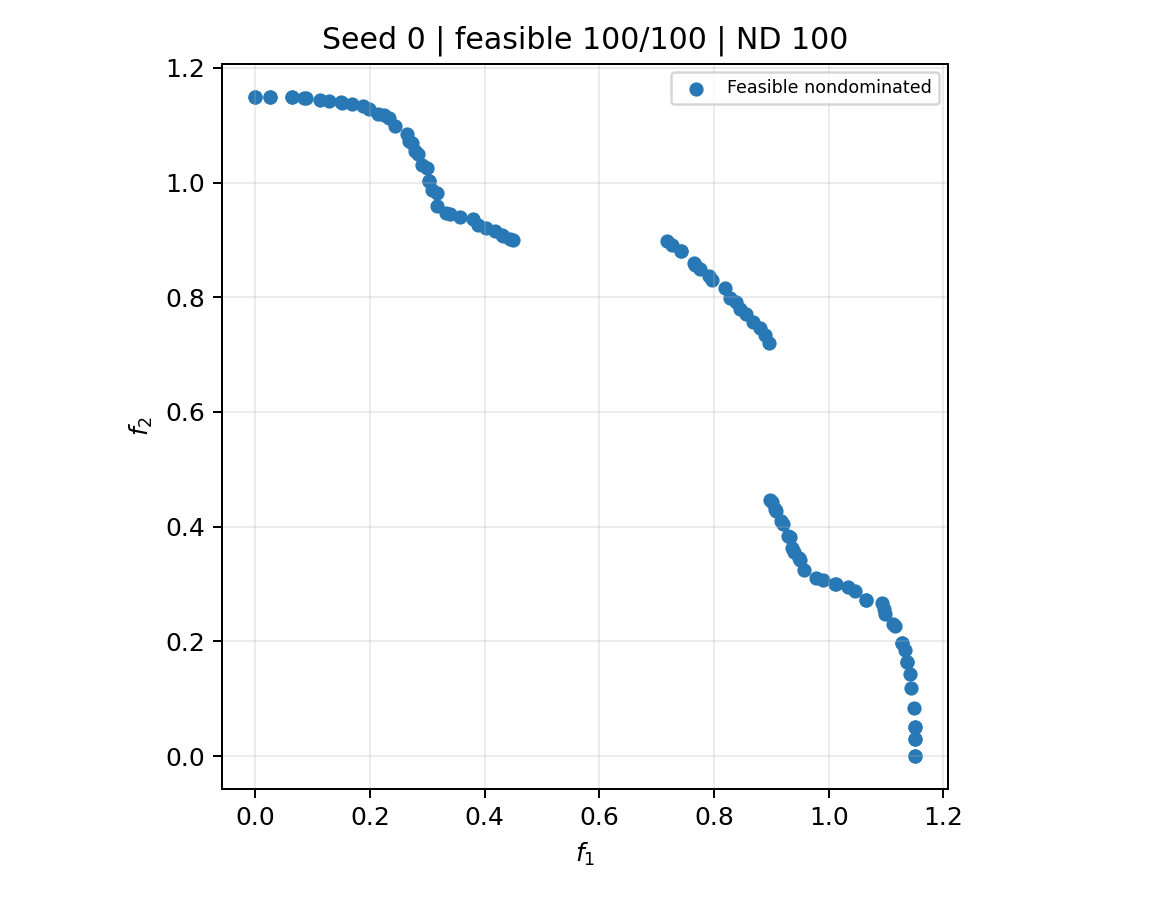

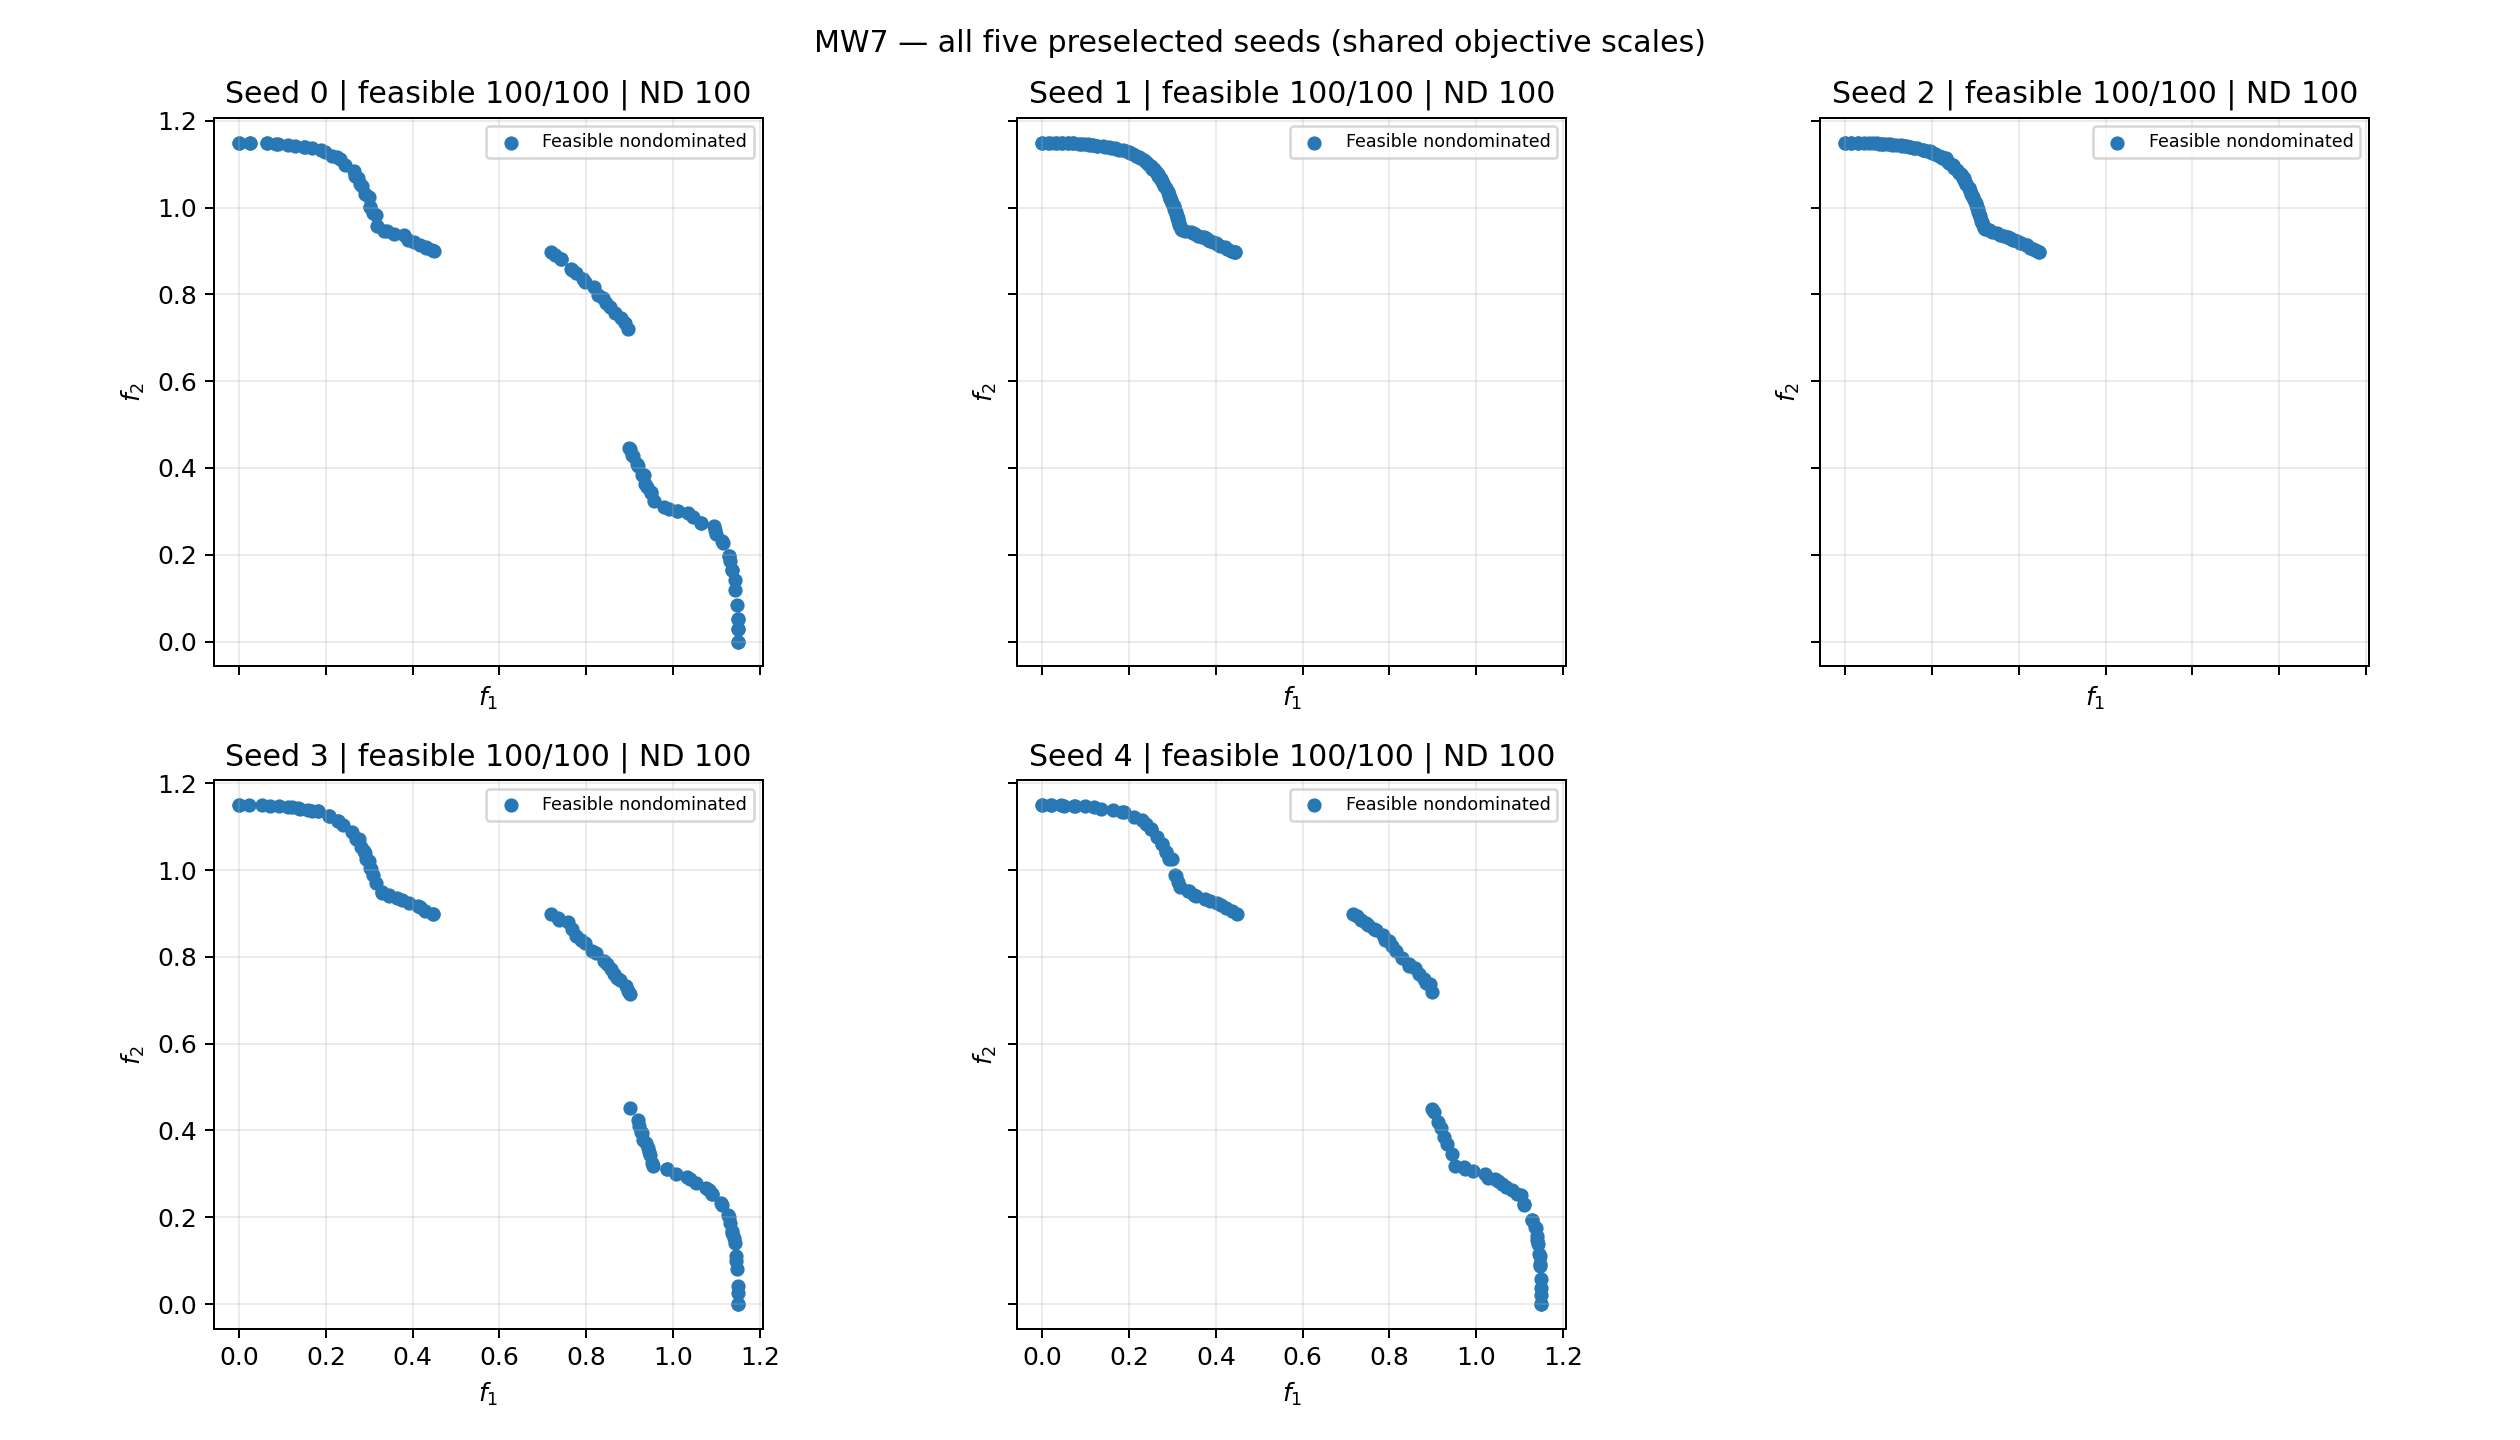

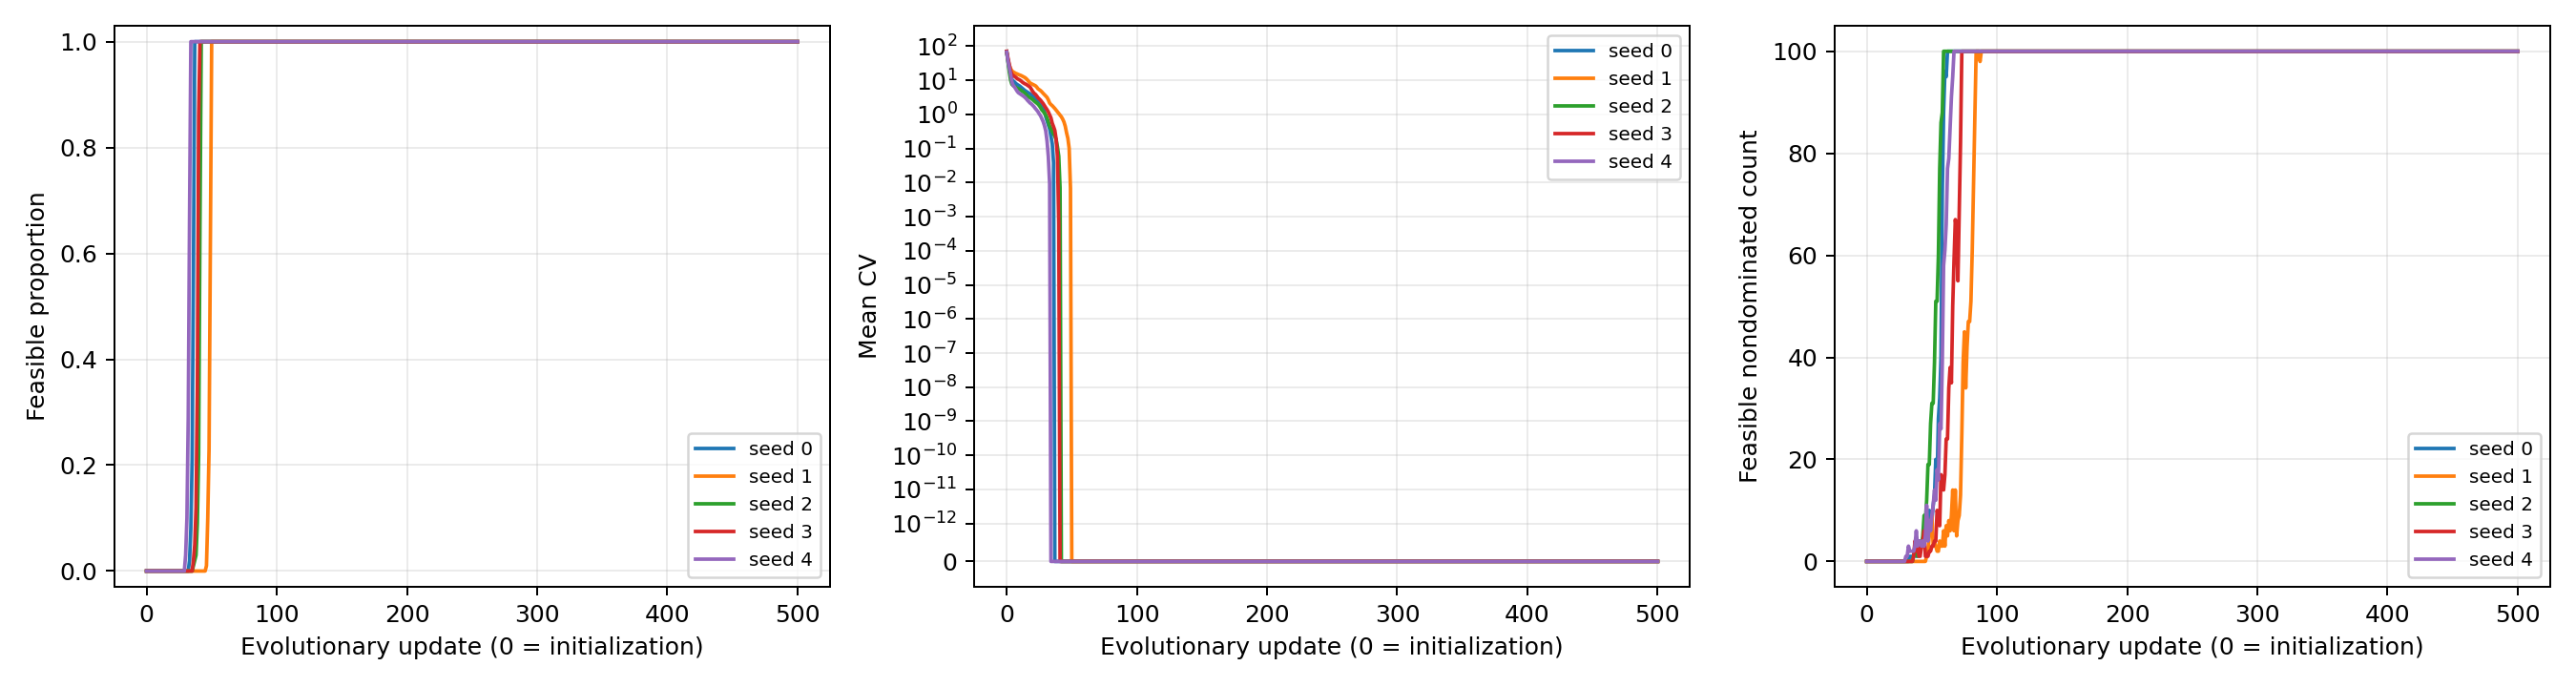

In [17]:
def task3_scatter(ax, result):
    f, cv = result["f"], result["cv"]
    feasible = cv <= result["metadata"]["parameters"]["cv_tol"]
    nd = result["nd_mask"]
    for mask, color, marker, label, size in (
            (~feasible, "#c44e52", "x", "Infeasible", 26),
            (feasible & ~nd, "#999999", "o", "Feasible dominated", 18),
            (nd, "#2878b5", "o", "Feasible nondominated", 22)):
        if mask.any():
            ax.scatter(f[mask, 0], f[mask, 1], color=color, marker=marker, s=size, label=label)
    ax.set(xlabel="$f_1$", ylabel="$f_2$",
           title=f"Seed {result['metadata']['seed']} | feasible {feasible.sum()}/{len(f)} | ND {nd.sum()}")
    ax.grid(alpha=0.25)
    ax.set_aspect("equal", adjustable="box")
    ax.legend(fontsize=7)


if task3_results:
    task3_figure_dir = TASK3_OUTPUT_DIR / "figures"
    task3_figure_dir.mkdir(exist_ok=True)
    task3_all_f = np.vstack([r["f"] for r in task3_results])
    task3_span = np.maximum(np.ptp(task3_all_f, axis=0), 0.1)
    task3_lower = task3_all_f.min(axis=0) - 0.05 * task3_span
    task3_upper = task3_all_f.max(axis=0) + 0.05 * task3_span

    task3_fig, task3_ax = plt.subplots(figsize=(6.5, 5))
    task3_scatter(task3_ax, task3_results[0])
    task3_ax.set_xlim(task3_lower[0], task3_upper[0])
    task3_ax.set_ylim(task3_lower[1], task3_upper[1])
    task3_fig.tight_layout()
    task3_fig.savefig(task3_figure_dir / "baseline_seed_0.png", dpi=180)
    task3_emit_figure("task3-plots", task3_figure_dir / "baseline_seed_0.png")
    plt.close(task3_fig)

    task3_fig, task3_axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True)
    for task3_ax, task3_result in zip(task3_axes.flat, task3_results):
        task3_scatter(task3_ax, task3_result)
        task3_ax.set_xlim(task3_lower[0], task3_upper[0])
        task3_ax.set_ylim(task3_lower[1], task3_upper[1])
    task3_axes.flat[-1].axis("off")
    task3_fig.suptitle("MW7 — all five preselected seeds (shared objective scales)")
    task3_fig.tight_layout()
    task3_fig.savefig(task3_figure_dir / "all_seeds.png", dpi=180)
    task3_emit_figure("task3-plots", task3_figure_dir / "all_seeds.png")
    plt.close(task3_fig)

    task3_fig, task3_axes = plt.subplots(1, 3, figsize=(15, 4))
    for task3_result in task3_results:
        h = task3_result["history"]
        generations = [row["generation"] for row in h]
        label = f"seed {task3_result['metadata']['seed']}"
        task3_axes[0].plot(generations, [row["feasible_ratio"] for row in h], label=label)
        task3_axes[1].plot(generations, [row["mean_cv"] for row in h], label=label)
        task3_axes[2].plot(generations, [row["feasible_nd_count"] for row in h], label=label)
    task3_axes[0].set(ylabel="Feasible proportion", ylim=(-0.03, 1.03))
    task3_axes[1].set_ylabel("Mean CV")
    task3_axes[1].set_yscale("symlog", linthresh=1e-12)
    task3_axes[2].set_ylabel("Feasible nondominated count")
    for task3_ax in task3_axes:
        task3_ax.set_xlabel("Evolutionary update (0 = initialization)")
        task3_ax.grid(alpha=0.25)
        task3_ax.legend(fontsize=8)
    task3_fig.tight_layout()
    task3_fig.savefig(task3_figure_dir / "search_history.png", dpi=180)
    task3_emit_figure("task3-plots", task3_figure_dir / "search_history.png")
    plt.close(task3_fig)


In [18]:
if task3_summary:
    task3_feasible_counts = np.array([row["feasible_count"] for row in task3_summary])
    task3_nd_counts = np.array([row["feasible_nd_count"] for row in task3_summary])
    task3_observations = (
        "# Task 3 — measured observations\n\n"
        f"Parameters: {json.dumps(TASK3_BASELINE, sort_keys=True)}. Seeds: {list(TASK3_SEEDS)}.\n\n"
        + task3_table + "\n"
        + f"Feasible count: mean {task3_feasible_counts.mean():.1f}, "
          f"sample SD {task3_feasible_counts.std(ddof=1):.1f}, "
          f"range {task3_feasible_counts.min()}–{task3_feasible_counts.max()}.\n\n"
        + f"Feasible nondominated count: mean {task3_nd_counts.mean():.1f}, "
          f"sample SD {task3_nd_counts.std(ddof=1):.1f}, "
          f"range {task3_nd_counts.min()}–{task3_nd_counts.max()}.\n\n"
        + "These counts describe feasibility and within-population nondominance, "
          "not convergence to the true PF or full segment coverage. All preselected "
          "seeds are shown. Interpret spatial gaps qualitatively until a validated "
          "numerical reference front is available.\n"
    )
    (TASK3_OUTPUT_DIR / "observations.md").write_text(task3_observations, encoding="utf-8")
    (TASK3_OUTPUT_DIR / "experiment_manifest.json").write_text(
        json.dumps(dict(algorithm_version=TASK3_ALGORITHM_VERSION, baseline=TASK3_BASELINE,
                        seeds=list(TASK3_SEEDS), mode=TASK3_MODE,
                        runs=[r["metadata"] for r in task3_results]), indent=2), encoding="utf-8")
    task3_emit_markdown("task3-observations", task3_observations)
    print("Artifacts ready for review:", TASK3_OUTPUT_DIR.resolve())


# Task 3 — measured observations

Parameters: {"cv_tol": 1e-12, "eta_c": 20.0, "eta_m": 20.0, "max_gen": 500, "pc": 0.8, "pm": 0.05, "pop_size": 100}. Seeds: [0, 1, 2, 3, 4].

| Seed | Feasible | Strict feasible | Feasible ND | Mean CV | Max CV | Evaluations | Seconds |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | 100 | 100 | 100 | 0 | 0 | 50100 | 2.6 |
| 1 | 100 | 100 | 100 | 0 | 0 | 50100 | 2.6 |
| 2 | 100 | 100 | 100 | 0 | 0 | 50100 | 2.6 |
| 3 | 100 | 100 | 100 | 0 | 0 | 50100 | 2.5 |
| 4 | 100 | 100 | 100 | 0 | 0 | 50100 | 2.8 |

Feasible count: mean 100.0, sample SD 0.0, range 100–100.

Feasible nondominated count: mean 100.0, sample SD 0.0, range 100–100.

These counts describe feasibility and within-population nondominance, not convergence to the true PF or full segment coverage. All preselected seeds are shown. Interpret spatial gaps qualitatively until a validated numerical reference front is available.


Artifacts ready for review: task3_results/baseline-v1


In [19]:
if task3_results:
    if [r["metadata"]["seed"] for r in task3_results] != list(TASK3_SEEDS):
        raise ValueError("Cannot export an incomplete or reordered baseline experiment")
    task3_artifact_names = [f"seed_{seed}.npz" for seed in TASK3_SEEDS]
    task3_artifact_names += [f"seed_{seed}_{suffix}.csv" for seed in TASK3_SEEDS
                            for suffix in ("population", "history")]
    task3_artifact_names += ["summary.csv", "observations.md", "experiment_manifest.json"]
    task3_artifact_names += ["figures/" + name for name in
                            ("baseline_seed_0.png", "all_seeds.png", "search_history.png")]
    task3_bundle = dict(schema_version=1, producer="task3/task3_mw7.py",
                        source_sha256=TASK3_SOURCE_SHA256,
                        algorithm_version=TASK3_ALGORITHM_VERSION,
                        mode=TASK3_MODE, baseline=TASK3_BASELINE, seeds=list(TASK3_SEEDS),
                        outputs_by_tag=TASK3_CAPTURED_OUTPUTS,
                        artifacts={name: hashlib.sha256((TASK3_OUTPUT_DIR / name).read_bytes()).hexdigest()
                                   for name in task3_artifact_names})
    task3_bundle_tmp = TASK3_OUTPUT_DIR / "notebook_outputs.tmp"
    task3_bundle_tmp.write_text(json.dumps(task3_bundle, ensure_ascii=False, indent=2), encoding="utf-8")
    task3_bundle_tmp.replace(TASK3_OUTPUT_DIR / "notebook_outputs.json")
    print("Python run complete. Assemble the Notebook without rerunning experiments:")
    print(f"python scripts/build_task3_notebook.py --results {TASK3_OUTPUT_DIR}")


## 7. Results analysis and discussion

We ran constrained NSGA-II with five random seeds using the same parameter settings. In all five runs, the entire population became feasible between generations 34 and 50, and every final individual had zero constraint violation. However, the final solution distributions differed considerably. Seeds 0, 3 and 4 found the three main branches shown in the reference figure, whereas all 100 solutions from seeds 1 and 2 were concentrated on the upper-left branch. The algorithm therefore found feasible solutions consistently, but did not consistently explore the different branches of the front.

We think the main reason for the missing branches is that, once the search becomes concentrated in one region, the selection and variation operators have difficulty spreading the population into other regions. For example, seeds 1 and 2 both ended with 100 nondominated solutions, but these solutions were mutually nondominated only within the upper-left branch. The algorithm could keep refining that part of the solution set without discovering the middle or lower-right branches. Reaching 100 nondominated solutions therefore did not mean that the problem had been adequately explored.

The constraint-handling rule helps explain why this can happen. Our implementation always prefers a feasible solution to an infeasible one. Once all 100 parents are feasible, an infeasible offspring will be discarded during environmental selection, even if its position could be useful for exploring a new region. This quickly establishes a feasible population, but also prevents infeasible intermediate solutions from surviving and contributing to later generations. If the population is concentrated near one branch at this stage, the search can become restricted to that region.

The crossover and mutation settings may reinforce this concentration. Both distribution indices were set to 20, so new solutions tend to remain relatively close to their parents. The mutation probability was 0.05 per variable; with 15 variables in MW7, this means that an average of only 0.75 variables are mutated in each offspring. When the parents are already concentrated on the upper-left branch, these operators are more likely to generate nearby solutions than to explore the other, more distant branches. The fact that seeds 1 and 2 still covered only the upper-left branch after 500 generations is consistent with this tendency towards local search.

Crowding distance cannot automatically recover the missing branches either. It is calculated from the solutions currently in the population and favors individuals in less crowded locations. For seeds 1 and 2, this can spread solutions along the upper-left branch, but it provides no information about the undiscovered middle and lower-right branches. In contrast, seeds 0, 3 and 4 ended with approximately 40, 20 and 40 individuals in the three regions, respectively. The same settings can therefore find several branches, but the outcome depends noticeably on the random search trajectory. Since we did not save the population positions at every generation, we cannot tell whether the missing branches were never found or were found earlier and subsequently lost.

To address this behavior, we would first try increasing search diversity, for example by using a larger population, increasing the mutation probability, or lowering the mutation distribution index so that offspring can move farther from the current population. A further algorithmic change would be to retain a small number of infeasible solutions with exploration potential instead of discarding all of them. In follow-up experiments, we would compare how consistently these changes find all three branches across several random seeds, while also recording the number of objective evaluations required. This would be more informative than comparing only the final numbers of feasible and nondominated solutions.


### TODO: Solve the Assigned Real-World Constrained Multi-Objective Optimization Problem (30 Marks)

Your group has been assigned one **real-world constrained multi-objective optimization (RCM) problem**. Check the [Google Sheet](https://docs.google.com/spreadsheets/d/16YdUPUa9-odsxajJ2FukP3yenpzy3Wl2gUPET8h2TDo/edit?usp=sharing) to identify your group’s assigned problem.

The complete mathematical formulation, including the objectives, constraints, variable bounds, and references, is available in the following paper:

> A. Kumar et al., “A benchmark-suite of real-world constrained multi-objective optimization problems and some baseline results,” *Swarm and Evolutionary Computation*, vol. 67, 2021. DOI: [10.1016/j.swevo.2021.100961](https://doi.org/10.1016/j.swevo.2021.100961).

A local copy is also included in the project ZIP file at `related papers/RCM.pdf`.

#### Core Project Tasks

Complete the following tasks for your assigned RCM problem:

- **Implement the Problem Class:** Implement the objectives, constraints, and decision-variable bounds of the assigned problem as a Python class.
- **Apply Constrained NSGA-II:** Use your constrained NSGA-II implementation to solve the assigned problem.
- **Conduct Parameter Analysis:** Systematically evaluate different population sizes, crossover and mutation probabilities, and maximum numbers of generations.
- **Analyze Algorithm Performance:** Discuss how these parameter choices affect convergence, solution diversity, and overall optimization performance.
- **Report the Final Results:** Present the Pareto-optimal solutions obtained using your best-performing parameter configuration and provide a critical discussion of the results.

# Task 4 - RCM20 Hydro-static Thrust Bearing Design

This part solves RCM20 with the constrained NSGA-II from Task 3. The problem
definition is the authors' public implementation: file `CEC2021_func.m`, branch
`func == 20`, in `CEC2021-RWCMOP.zip` from
<https://github.com/P-N-Suganthan/2021-RW-MOP>, which accompanies the RCM
benchmark paper (Kumar et al., Swarm and Evolutionary Computation 67, 2021).

The equations printed in the supplementary material (`RCM supp.pdf`, section
1.1.20) differ from this code. For example, `P` is printed as
`(log10 log10(8.122e6 mu + 0.8) + 3.55)/10.04` instead of
`(log10 log10(8.122e6 mu + 0.8) - 10.04)/(-3.55)`; the pressure constraint has the
opposite direction (`P0 >= 1000` instead of `P0 <= 1000`); and the temperature
constraint bounds `P0` instead of the temperature rise `dT`. Implemented exactly
as printed, that version gives `P0 < 0` wherever its formulas are defined, which
contradicts `P0 >= 1000`, so it has no feasible point. Following the TA's advice,
we use the repository code.

The algorithm returns *approximate* non-dominated solutions: feasible points that
no other point found by the run dominates; they are not guaranteed to be
Pareto-optimal.

In [20]:
import hashlib
import json
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Results and figures are written next to this notebook.
RESULT_DIR, FIGURE_DIR = Path("results"), Path("figures")
RESULT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

## 4.1 Model

The authors' branch, for reference:

```matlab
elseif func == 20
    %% Hydro-static thrust bearing design problem
    R = x(:,1); Ro = x(:,2);  mu = x(:,3); Q = x(:,4);
    gamma = 0.0307; C = 0.5; n = -3.55; C1 = 10.04;
    Ws = 101000; Pmax = 1000; delTmax = 50; hmin = 0.001;
    gg = 386.4; N = 750;
    P    = (log10(log10(8.122*1e6.*mu+0.8))-C1)./n;
    delT = 2.*(10.^P-560);
    Ef   = 9336.*Q.*gamma.*C.*delT;
    h    = (2.*pi.*N./60).^2.*2.*pi.*mu./Ef.*(R.^4./4-Ro.^4./4)-1e-5;
    Po   = (6.*mu.*Q./(pi.*h.^3)).*log(R./Ro);
    W    = pi.*Po./2.*(R.^2-Ro.^2)./(log(R./Ro)-1e-5);
    %%  objective function
    f = zeros(ps,2);
    f(:,1) = (Q.*Po./0.7+Ef)./12;
    f(:,2) = gamma./(gg.*Po).*(Q./(2.*pi.*R.*h));
    %%  constraints
    g(:,1) = Ws-W;
    g(:,2) = Po-Pmax;
    g(:,3) = delT-delTmax;
    g(:,4) = hmin-h;
    g(:,5) = Ro-R;
    g(:,6) = f(:,2)-0.001;
    g(:,7) = W./(pi.*(R.^2-Ro.^2)+1e-5)-5000;
    h      = zeros(ps,0);
```

Bounds from `Cal_par.m`: `R, Ro` in `[1, 16]`, `mu` in `[1e-6, 16e-6]`, `Q` in
`[1, 16]`. Objectives: `f1 = (Q*Po/0.7 + Ef)/12`, a pumping term plus a friction
term (the power loss), and `f2 = gamma*Q/(gg*Po*2*pi*R*h)`. All constants and the
three `1e-5` terms of the code are kept. All seven constraints are in
`g(x) <= 0` form.

In [21]:
class RCM20AuthorCode:
    """RCM20 exactly as defined by CEC2021_func.m, func == 20.

    ``evaluate`` follows the Task-3 contract: it returns ``f[N, 2]`` and
    ``c[N, 7]`` with ``c >= 0``, where ``c_j = max(g_j, 0)``.  ``raw`` returns the
    unmodified MATLAB quantities, including non-finite ones, and is what the
    report quotes for the final solutions.
    """

    # Constants of the evaluation adapter (see section 2).  They never enter the
    # model itself; they only bound what is handed back to the optimiser.
    VIOLATION_CAP = 1e12      # per-constraint ceiling for a *well-defined* point
    OBJECTIVE_CAP = 1e12      # |f| ceiling for a well-defined point
    UNDEFINED_VIOLATION = 1e13  # per-constraint value for an undefined point

    def __init__(self):
        self.name = "RCM20 hydro-static thrust bearing (author MATLAB source)"
        self.n_var = 4
        self.n_obj = 2
        self.n_con = 7
        self.lower = np.array([1.0, 1.0, 1e-6, 1.0])
        self.upper = np.array([16.0, 16.0, 16e-6, 16.0])
        self.var_names = ("R", "Ro", "mu", "Q")
        self.con_names = ("g1: Ws - W <= 0", "g2: Po - Pmax <= 0",
                          "g3: delT - delTmax <= 0", "g4: hmin - h <= 0",
                          "g5: Ro - R <= 0", "g6: f2 - 0.001 <= 0",
                          "g7: W/(pi(R^2-Ro^2)+1e-5) - 5000 <= 0")
        self.reset_counters()

    def reset_counters(self):
        self.n_eval = 0
        self.n_undefined = 0
        self.n_capped_f = 0
        self.n_capped_c = 0
        self.last_defined = None

    # -- the model itself ---------------------------------------------------
    @staticmethod
    def raw(x):
        """Return (f, g, intermediates) exactly as the MATLAB branch computes them.

        No guards, no clipping: NaN and +-inf are passed through so that
        undefined points stay visibly undefined.
        """
        x = np.atleast_2d(np.asarray(x, dtype=float))
        R, Ro, mu, Q = x[:, 0], x[:, 1], x[:, 2], x[:, 3]
        gamma, C, n, C1 = 0.0307, 0.5, -3.55, 10.04
        Ws, Pmax, delTmax, hmin = 101000.0, 1000.0, 50.0, 0.001
        gg, N = 386.4, 750.0
        with np.errstate(all="ignore"):
            P = (np.log10(np.log10(8.122e6 * mu + 0.8)) - C1) / n
            delT = 2.0 * (10.0 ** P - 560.0)
            Ef = 9336.0 * Q * gamma * C * delT
            h = (2.0 * np.pi * N / 60.0) ** 2 * 2.0 * np.pi * mu / Ef * (R ** 4 / 4.0 - Ro ** 4 / 4.0) - 1e-5
            Po = (6.0 * mu * Q / (np.pi * h ** 3)) * np.log(R / Ro)
            W = np.pi * Po / 2.0 * (R ** 2 - Ro ** 2) / (np.log(R / Ro) - 1e-5)
            f1 = (Q * Po / 0.7 + Ef) / 12.0
            f2 = gamma / (gg * Po) * (Q / (2.0 * np.pi * R * h))
            g = np.column_stack([
                Ws - W,
                Po - Pmax,
                delT - delTmax,
                hmin - h,
                Ro - R,
                f2 - 0.001,
                W / (np.pi * (R ** 2 - Ro ** 2) + 1e-5) - 5000.0,
            ])
        f = np.column_stack([f1, f2])
        return f, g, dict(P=P, delT=delT, Ef=Ef, h=h, Po=Po, W=W)

    @classmethod
    def defined_mask(cls, f, g):
        """A point is *defined* when every objective and every constraint is finite."""
        return np.isfinite(f).all(axis=1) & np.isfinite(g).all(axis=1)

    # -- the Task-3 interface ----------------------------------------------
    def evaluate(self, x):
        f_raw, g_raw, _ = self.raw(x)
        defined = self.defined_mask(f_raw, g_raw)

        c = np.maximum(g_raw, 0.0)
        capped_c = defined[:, None] & (c > self.VIOLATION_CAP)
        c = np.where(capped_c, self.VIOLATION_CAP, c)

        capped_f = defined[:, None] & (np.abs(f_raw) > self.OBJECTIVE_CAP)
        f = np.where(capped_f, np.sign(f_raw) * self.OBJECTIVE_CAP, f_raw)

        # Undefined points: flagged, never feasible, and strictly worse on CV than
        # any defined point (7 * 1e13 > 7 * VIOLATION_CAP).  Their objectives are
        # replaced only because the Task-3 evaluator rejects non-finite values;
        # the replacement is never reported as a result.
        f = np.where(defined[:, None], f, self.OBJECTIVE_CAP)
        c = np.where(defined[:, None], c, self.UNDEFINED_VIOLATION)

        self.n_eval += len(x)
        self.n_undefined += int((~defined).sum())
        self.n_capped_f += int(capped_f.any(axis=1).sum())
        self.n_capped_c += int(capped_c.any(axis=1).sum())
        self.last_defined = defined
        return f, c

    # -- helpers used by the analysis --------------------------------------
    def report(self, x):
        """True model values plus the validity flag, for anything that gets quoted."""
        f, g, extra = self.raw(x)
        defined = self.defined_mask(f, g)
        cv = np.where(defined, np.maximum(g, 0.0).sum(axis=1), np.nan)
        return dict(f=f, g=g, cv=cv, defined=defined, **extra)

### Constraint handling and numerical safeguards

The violation of constraint `j` is `c_j = max(g_j, 0)` and `CV = sum_j c_j`; a
point is feasible when `CV <= 1e-12`, the Task 3 tolerance. MW7's conversion
`where(c < 0, -c, 0)` is written for `>= 0` constraints and is not reused here.

The model divides by `h**3`, `Po`, `Ef` and `log(R/Ro) - 1e-5`, so some points give
non-finite values (for example `R = Ro`). Such *undefined* points get a
violation of `1e13` per constraint, more than any defined point can receive, so
they are never feasible; their objectives are set to `1e12` only because the
Task 3 evaluator does not accept NaN. For defined points, violations and
`|f_i|` are capped at `1e12` so that `CV` cannot overflow. The cap does not change
which points are feasible, but it can change the order between extremely
infeasible candidates. Every reported solution is re-checked with the uncapped
formulas.

In [22]:
REGRESSION_X = np.array([[5.9585, 5.3912, 5.3825e-6, 2.2783]])
REGRESSION_F = (1621.3107, 3.64051e-6)   # value of the author model at REGRESSION_X, computed outside this notebook

prob = RCM20AuthorCode()
assert np.array_equal(prob.lower, [1.0, 1.0, 1e-6, 1.0]) and np.array_equal(prob.upper, [16.0, 16.0, 16e-6, 16.0])

# Regression point: a known feasible point of the author model.
rep = prob.report(REGRESSION_X)
assert abs(rep["f"][0, 0] - REGRESSION_F[0]) / REGRESSION_F[0] < 1e-6
assert abs(rep["f"][0, 1] - REGRESSION_F[1]) / REGRESSION_F[1] < 1e-5
assert np.all(rep["g"][0] <= 0.0)

# R == Ro is undefined (f2 infinite): flagged, finite after the adapter, never feasible.
f_raw, g_raw, _ = prob.raw([[5.0, 5.0, 5e-6, 2.0]])
f_ad, c_ad = prob.evaluate([[5.0, 5.0, 5e-6, 2.0]])
assert not prob.defined_mask(f_raw, g_raw).any() and np.isfinite(c_ad).all() and c_ad.sum() > 0

# Violations use c = max(g, 0), not MW7's sign flip.
_, g_probe, _ = prob.raw([[8.0, 4.0, 6e-6, 3.0]])
assert np.allclose(prob.evaluate([[8.0, 4.0, 6e-6, 3.0]])[1][0], np.maximum(g_probe[0], 0.0))

print(f"regression point: f = ({rep['f'][0, 0]:.4f}, {rep['f'][0, 1]:.6e}), all seven g <= 0")
print("undefined point R = Ro handled; violation convention c = max(g, 0): checks passed")

regression point: f = (1621.3107, 3.640511e-06), all seven g <= 0
undefined point R = Ro handled; violation convention c = max(g, 0): checks passed


## 4.2 Experiment setup

The constrained NSGA-II is the `CNSGA2` class from Task 3, used without changes.
`pm` is applied per variable and `pc` once per parent pair. A run with population
`N` and `G` generations uses `N x (G + 1)` evaluations, including the initial
population.

The study is staged. **Stage A** varies one parameter at a time around the
baseline (`N = 100, G = 500, pc = 0.9, pm = 0.25`). **Stage B** keeps the budget
at approximately 200,000 evaluations (200,020 to 200,400) and only changes the
split between `N` and `G`, because larger `N` or `G` also means more
evaluations. **Stage C** combines the two best levels of `N` (from Stage B) and of
`pc` and `pm` (from Stage A) at exactly 200,000 evaluations. The configuration
with the highest median hypervolume is selected; if several are within 2% of
it, the one with more distinct solutions is chosen. It is then rerun on ten new
seeds (100-109) next to two baselines. Stages A-C use seeds 0-4.

**Measures.** Each run is classified as having no feasible solution, feasible
solutions with hypervolume 0, or feasible solutions with positive hypervolume.
The hypervolume (HV) is the area of normalised objective space dominated by a
run's feasible non-dominated solutions, bounded by the reference point
`(1.1, 1.1)`; larger is better. The normalisation uses the extent of the pooled
non-dominated solutions of Stages A and B and is then kept fixed, so HV values
are only comparable within this study. NSGA-II keeps duplicate individuals, so
we count *distinct* solutions (exactly equal decision vectors are merged) and
also report the largest gap between neighbouring distinct solutions. The gap
describes spacing inside the obtained set, not how much of the front is covered.

In [23]:
# All formal experiment parameters.
BASELINE = dict(pop_size=100, max_gen=500, pc=0.9, pm=0.25, eta_c=20.0, eta_m=20.0, cv_tol=1e-12)
SEEDS = (0, 1, 2, 3, 4)               # Stages A-C and the budget analysis
FINAL_SEEDS = tuple(range(100, 110))  # confirmation, not used for selection
POP_LEVELS = (20, 50, 100, 200, 400)
PC_LEVELS = (0.0, 0.3, 0.6, 0.8, 0.9, 1.0)
PM_LEVELS = (0.0, 0.05, 0.1, 0.25, 0.5, 1.0)
GEN_LEVELS = (50, 100, 250, 500, 1000, 2000)
BUDGET = 200_000
BUDGET_SPLITS = ((20, 10_000), (50, 4000), (100, 2000), (200, 1000), (400, 500))
CONFIG_KEYS = ("pop_size", "max_gen", "pc", "pm", "eta_c", "eta_m", "cv_tol")

In [24]:
def config_label(config):
    return (f"pop{config['pop_size']}_gen{config['max_gen']}"
            f"_pc{config['pc']:g}_pm{config['pm']:g}"
            f"_ec{config['eta_c']:g}_em{config['eta_m']:g}")


def distinct_rows(x, f):
    """Exact de-duplication on the decision vector; order of first appearance kept."""
    x = np.asarray(x, dtype=float).reshape(-1, 4)
    f = np.asarray(f, dtype=float).reshape(-1, 2)
    if len(x) == 0:
        return x, f
    _, first = np.unique(x, axis=0, return_index=True)
    first = np.sort(first)
    return x[first], f[first]


def nondominated_mask(f):
    f = np.asarray(f, dtype=float).reshape(-1, 2)
    if len(f) == 0:
        return np.zeros(0, dtype=bool)
    dominated = np.any(np.all(f[:, None, :] <= f[None, :, :], axis=2)
                       & np.any(f[:, None, :] < f[None, :, :], axis=2), axis=0)
    return ~dominated


def run_one(config, seed, prob_factory=RCM20AuthorCode, progress_every=0):
    """One CNSGA2 run.  Never raises: a failure is recorded like any other run.

    The record is kept in memory: the evaluation count, the final population
    (x, raw f, CV), which members are feasible and non-dominated, and the
    per-generation history.
    """
    record = dict(config={k: config[k] for k in CONFIG_KEYS},
                  seed=seed, label=config_label(config), status="ok")
    prob = prob_factory()
    optimizer = CNSGA2(pop_size=config["pop_size"], pc=config["pc"], pm=config["pm"],
                       eta_c=config["eta_c"], eta_m=config["eta_m"],
                       cv_tol=config["cv_tol"], seed=seed)
    started = time.perf_counter()
    try:
        result = optimizer.run(prob, max_gen=config["max_gen"], progress_every=progress_every)
    except Exception as exc:                       # keep failures instead of dropping them
        record.update(status="failed", error=f"{type(exc).__name__}: {exc}",
                      elapsed_seconds=time.perf_counter() - started,
                      n_evals=optimizer.n_evals, n_undefined=prob.n_undefined)
        return record

    # Every objective evaluation is counted twice, independently: by CNSGA2 and by
    # the problem object.  Both must equal pop_size * (max_gen + 1), i.e. the
    # initial population plus one offspring population per generation.
    expected_evals = config["pop_size"] * (config["max_gen"] + 1)
    assert result["n_evals"] == prob.n_eval == expected_evals, \
        (result["n_evals"], prob.n_eval, expected_evals)

    x = np.asarray(result["x"])
    truth = prob.report(x)                         # raw model values for everything quoted
    feasible = result["cv"] <= config["cv_tol"]
    if feasible.any():
        assert truth["defined"][feasible].all(), "a point was called feasible but is undefined"
        assert np.array_equal(truth["f"][feasible], result["f"][feasible]), \
            "adapter altered the objectives of a feasible point"
    front = feasible & np.asarray(result["nd_mask"])
    history = {key: [h[key] for h in result["history"]] for key in result["history"][0]}
    record.update(
        elapsed_seconds=float(result["elapsed_seconds"]),
        n_evals=int(result["n_evals"]),
        n_undefined=int(prob.n_undefined), n_capped_f=int(prob.n_capped_f),
        n_capped_c=int(prob.n_capped_c),
        feasible_count=int(feasible.sum()), feasible_ratio=float(feasible.mean()),
        min_cv=float(result["cv"].min()), mean_cv=float(result["cv"].mean()),
        f1_min=float(truth["f"][feasible, 0].min()) if feasible.any() else None,
        f2_min=float(truth["f"][feasible, 1].min()) if feasible.any() else None,
        final_x=x.tolist(), final_f=truth["f"].tolist(), final_cv=result["cv"].tolist(),
        front_index=np.flatnonzero(front).tolist(),
        history=history,
    )
    return record


RUN_REGISTRY = {}    # (label, seed) -> record; one entry per distinct run, this session only
RUN_REQUESTS = []    # every (label, seed) any stage asked for, in order


def get_run(config, seed):
    """Each (configuration, seed) is run once.  A later request for the same pair
    reuses that run: the optimiser is deterministic for a given seed, so it would
    give the identical result."""
    key = (config_label(config), seed)
    RUN_REQUESTS.append(key)
    if key not in RUN_REGISTRY:
        RUN_REGISTRY[key] = run_one(config, seed)
    return RUN_REGISTRY[key]


def run_sweep(configs, seeds=SEEDS, note=""):
    records, started = [], time.perf_counter()
    reused = 0
    for config in configs:
        for seed in seeds:
            reused += (config_label(config), seed) in RUN_REGISTRY
            records.append(get_run(config, seed))
    elapsed = time.perf_counter() - started
    failures = [r for r in records if r["status"] != "ok"]
    print(f"{note}: {len(records)} runs ({reused} reused from an earlier stage), "
          f"{elapsed:.1f}s, {len(failures)} errors")
    for failure in failures:
        print(f"   ERROR {failure['label']} seed {failure['seed']}: {failure['error']}")
    return records

In [25]:
def front_records(record):
    """Feasible non-dominated members of the final population (duplicates kept)."""
    if record["status"] != "ok" or not record["front_index"]:
        return np.empty((0, 4)), np.empty((0, 2))
    index = record["front_index"]
    return (np.asarray(record["final_x"], dtype=float)[index],
            np.asarray(record["final_f"], dtype=float)[index])


def front_distinct(record):
    return distinct_rows(*front_records(record))


def nd_counts(record):
    x, _ = front_records(record)
    return len(x), len(distinct_rows(*front_records(record))[0])


def pooled_box(records):
    """Extent of the pooled best-known front (distinct solutions) of `records`."""
    parts = [front_distinct(r)[1] for r in records if r["status"] == "ok"]
    parts = [p for p in parts if len(p)]
    if not parts:
        return None
    points = np.unique(np.vstack(parts), axis=0)
    front = points[nondominated_mask(points)]
    return dict(ideal=front.min(axis=0).tolist(), nadir=front.max(axis=0).tolist(),
                n_pooled_distinct=int(len(points)), n_front=int(len(front)))


def hypervolume_2d(points, reference=(1.1, 1.1)):
    """Exact 2-D hypervolume for minimisation, dominated region below `reference`."""
    points = np.asarray(points, dtype=float).reshape(-1, 2)
    points = points[np.all(points < np.asarray(reference), axis=1)]
    if len(points) == 0:
        return 0.0
    points = points[nondominated_mask(points)]
    points = points[np.argsort(points[:, 0], kind="stable")]
    volume, previous = 0.0, reference[1]
    for f1, f2 in points:
        volume += (reference[0] - f1) * (previous - f2)
        previous = f2
    return float(volume)


def _normalise(f, box):
    ideal, nadir = np.asarray(box["ideal"]), np.asarray(box["nadir"])
    span = np.where(nadir - ideal > 0, nadir - ideal, 1.0)
    return (np.asarray(f, dtype=float).reshape(-1, 2) - ideal) / span


def normalised_hv(record, box, reference=(1.1, 1.1), use_records=False):
    if box is None or record["status"] != "ok":
        return 0.0
    _, f = front_records(record) if use_records else front_distinct(record)
    return hypervolume_2d(_normalise(f, box), reference) if len(f) else 0.0


def largest_gap(record, box):
    """Diversity indicator: the largest distance between neighbouring distinct
    solutions (sorted by f1) in normalised objective space.  Smaller means fewer
    holes in the front; NaN if the run has fewer than two distinct solutions."""
    _, f = front_distinct(record)
    if box is None or len(f) < 2:
        return float("nan")
    z = _normalise(f, box)
    z = z[np.argsort(z[:, 0], kind="stable")]
    return float(np.max(np.hypot(*np.diff(z, axis=0).T)))


def run_category(record, box):
    if record["status"] != "ok":
        return "error"
    if record["feasible_count"] == 0:
        return "no feasible solution"
    return "feasible, HV = 0" if normalised_hv(record, box) == 0.0 else "feasible, HV > 0"


def summarise(records, box, label_key="label"):
    """Per-configuration summary across seeds (each (label, seed) counted once)."""
    groups = {}
    for record in records:
        groups.setdefault(record[label_key], {})[record["seed"]] = record
    rows = []
    for label, by_seed in groups.items():
        runs = list(by_seed.values())
        ok = [r for r in runs if r["status"] == "ok"]
        found = [r for r in ok if r["feasible_count"] > 0]
        hv = np.array([normalised_hv(r, box) for r in ok]) if ok else np.array([0.0])
        counts = np.array([nd_counts(r) for r in ok]) if ok else np.zeros((1, 2))
        gaps = np.array([largest_gap(r, box) for r in ok]) if ok else np.array([np.nan])
        row = dict(label=label, n_runs=len(runs), n_error=len(runs) - len(ok),
                   n_found=len(found), n_no_feasible=len(ok) - len(found),
                   n_feasible_hv0=sum(run_category(r, box) == "feasible, HV = 0" for r in ok),
                   **{k: runs[0]["config"][k] for k in CONFIG_KEYS})
        if ok:
            row.update(
                evals=int(np.median([r["n_evals"] for r in ok])),
                seconds=float(np.median([r["elapsed_seconds"] for r in ok])),
                feasible_ratio=float(np.median([r["feasible_ratio"] for r in ok])),
                nd_records=float(np.median(counts[:, 0])),
                nd_distinct=float(np.median(counts[:, 1])),
                gap_median=(float(np.nanmedian(gaps)) if np.isfinite(gaps).any() else float("nan")),
                f1_min=float(np.median([r["f1_min"] for r in found])) if found else float("nan"),
                f2_min=float(np.median([r["f2_min"] for r in found])) if found else float("nan"),
                hv_median=float(np.median(hv)), hv_min=float(hv.min()), hv_max=float(hv.max()),
                undefined=int(np.sum([r["n_undefined"] for r in ok])),
                capped=int(np.sum([r["n_capped_f"] + r["n_capped_c"] for r in ok])))
        rows.append(row)
    return rows


def print_table(rows, columns, title=""):
    if title:
        print(f"\n{title}")
    headers = [name for name, _ in columns]
    cells = [[fmt(row) for _, fmt in columns] for row in rows]
    widths = [max([len(h)] + [len(c[i]) for c in cells]) for i, h in enumerate(headers)]
    line = "  ".join(h.rjust(w) for h, w in zip(headers, widths))
    print(line)
    print("-" * len(line))
    for cell in cells:
        print("  ".join(value.rjust(w) for value, w in zip(cell, widths)))


FMT = {
    "label": ("configuration", lambda r: r["label"]),
    "pop": ("pop", lambda r: str(r["pop_size"])),
    "gen": ("gen", lambda r: str(r["max_gen"])),
    "pc": ("pc", lambda r: f"{r['pc']:g}"),
    "pm": ("pm", lambda r: f"{r['pm']:g}"),
    "evals": ("evals", lambda r: f"{r.get('evals', 0):,}"),
    "seconds": ("s/run", lambda r: f"{r.get('seconds', float('nan')):.2f}"),
    "found": ("found feas.", lambda r: f"{r['n_found']}/{r['n_runs']}"),
    "hv0": ("feas.,HV=0", lambda r: str(r["n_feasible_hv0"])),
    "feas": ("feas% med", lambda r: f"{100 * r.get('feasible_ratio', 0):.0f}"),
    "ndrec": ("ND rec", lambda r: f"{r.get('nd_records', 0):.0f}"),
    "nddist": ("ND dist", lambda r: f"{r.get('nd_distinct', 0):.0f}"),
    "gap": ("max gap", lambda r: f"{r.get('gap_median', float('nan')):.3f}"),
    "f1": ("best f1", lambda r: f"{r.get('f1_min', float('nan')):.2f}"),
    "f2": ("best f2", lambda r: f"{r.get('f2_min', float('nan')):.4e}"),
    "hv": ("HV med", lambda r: f"{r.get('hv_median', 0):.4f}"),
    "hvrange": ("HV min-max", lambda r: f"{r.get('hv_min', 0):.3f}-{r.get('hv_max', 0):.3f}"),
    "undef": ("undef", lambda r: str(r.get("undefined", 0))),
    "capped": ("capped", lambda r: str(r.get("capped", 0))),
    "err": ("error", lambda r: str(r.get("n_error", 0))),
}
RESULT_COLUMNS = ("evals", "seconds", "found", "hv0", "feas", "ndrec", "nddist", "gap",
                  "f1", "f2", "hv", "hvrange")
TABLE_NOTE = ("found feas. = runs whose final population holds >= 1 feasible point; "
              "feas.,HV=0 = runs with feasible points all outside the HV reference; "
              "feas% med = median over seeds of the feasible share of the final population; "
              "ND rec / ND dist = median feasible non-dominated records / distinct solutions; "
              "max gap = median largest gap between neighbouring distinct solutions (normalised); "
              "best f1, best f2 = median over the runs that found feasible points")

In [26]:
# Evaluation count and the prefix property: a run stopped after 10 generations is
# exactly the first 10 generations of the same seed run for 20, so the G sweep
# follows the same runs to different stopping points.
short_run = run_one(dict(BASELINE, pop_size=20, max_gen=10), seed=2026)
long_run = run_one(dict(BASELINE, pop_size=20, max_gen=20), seed=2026)
assert long_run["n_evals"] == 20 * 21
assert all(long_run["history"][k][:11] == short_run["history"][k] for k in short_run["history"])
print("evaluation count N x (G + 1) and prefix property: checked")

evaluation count N x (G + 1) and prefix property: checked


## 4.3 Parameter study

In [27]:
stage_a_configs = []
for levels, key in ((POP_LEVELS, "pop_size"), (PC_LEVELS, "pc"),
                    (PM_LEVELS, "pm"), (GEN_LEVELS, "max_gen")):
    for level in levels:
        config = dict(BASELINE, **{key: level})
        if all(config_label(existing) != config_label(config) for existing in stage_a_configs):
            stage_a_configs.append(config)

print(f"Stage A: {len(stage_a_configs)} distinct configurations x {len(SEEDS)} seeds")
stage_a = run_sweep(stage_a_configs, note="Stage A (one factor at a time)")

Stage A: 20 distinct configurations x 5 seeds


Stage A (one factor at a time): 100 runs (0 reused from an earlier stage), 406.3s, 0 errors


In [28]:
stage_b_configs = [dict(BASELINE, pop_size=pop, max_gen=gen) for pop, gen in BUDGET_SPLITS]
for config in stage_b_configs:
    evals = config["pop_size"] * (config["max_gen"] + 1)
    assert abs(evals - BUDGET) <= config["pop_size"], (config, evals)
print(f"Stage B: budget about {BUDGET:,} evaluations, "
      f"{len(stage_b_configs)} splits x {len(SEEDS)} seeds")
stage_b = run_sweep(stage_b_configs, note="Stage B (budget-controlled)")

Stage B: budget about 200,000 evaluations, 5 splits x 5 seeds


Stage B (budget-controlled): 25 runs (10 reused from an earlier stage), 162.3s, 0 errors


In [29]:
BOX = pooled_box(stage_a + stage_b)
if BOX is None:
    print("no feasible solution in Stages A+B - hypervolume cannot be normalised")
else:
    print(f"normalisation box frozen from Stages A+B: ideal = {np.array(BOX['ideal'])}, "
          f"nadir = {np.array(BOX['nadir'])}")
    print(f"  from {BOX['n_pooled_distinct']} distinct feasible non-dominated solutions "
          f"-> {BOX['n_front']} on the pooled front")

stage_a_rows = summarise(stage_a, BOX)
by_label = {row["label"]: row for row in stage_a_rows}
baseline_label = config_label(BASELINE)

for factor, key, levels in (("Population size", "pop_size", POP_LEVELS),
                            ("Crossover probability pc", "pc", PC_LEVELS),
                            ("Mutation probability pm (per variable)", "pm", PM_LEVELS),
                            ("Maximum generations", "max_gen", GEN_LEVELS)):
    rows = [by_label[config_label(dict(BASELINE, **{key: level}))] for level in levels]
    columns = [FMT[{"pop_size": "pop", "pc": "pc", "pm": "pm", "max_gen": "gen"}[key]]]
    columns += [FMT[k] for k in RESULT_COLUMNS]
    print_table(rows, columns,
                title=f"Stage A - {factor} (others at baseline pop={BASELINE['pop_size']}, "
                      f"gen={BASELINE['max_gen']}, pc={BASELINE['pc']}, pm={BASELINE['pm']}; "
                      f"{len(SEEDS)} seeds)")
print(f"\n{TABLE_NOTE}")

stage_b_rows = summarise(stage_b, BOX)
print_table(sorted(stage_b_rows, key=lambda r: r["pop_size"]),
            [FMT["pop"], FMT["gen"]] + [FMT[k] for k in RESULT_COLUMNS],
            title=f"Stage B - fixed budget of about {BUDGET:,} evaluations ({len(SEEDS)} seeds)")

normalisation box frozen from Stages A+B: ideal = [1.62588344e+03 2.74983736e-06], nadir = [1.05028743e+04 3.65357429e-06]
  from 8954 distinct feasible non-dominated solutions -> 475 on the pooled front

Stage A - Population size (others at baseline pop=100, gen=500, pc=0.9, pm=0.25; 5 seeds)
pop    evals  s/run  found feas.  feas.,HV=0  feas% med  ND rec  ND dist  max gap  best f1     best f2  HV med   HV min-max
---------------------------------------------------------------------------------------------------------------------------
 20   10,020   0.42          5/5           2        100      20       19    0.985  2827.30  3.1062e-06  0.5405  0.000-0.567
 50   25,050   1.11          5/5           0        100      50       46    0.236  1861.99  3.1089e-06  0.6349  0.362-0.736
100   50,100   2.65          5/5           0        100     100       86    0.135  1736.65  3.0210e-06  0.7113  0.608-0.747
200  100,200   7.79          5/5           0        100     200      157    0.071  17

In [30]:
def best_levels(rows, levels, label_of, n=2):
    """Top `n` levels by median HV, rows looked up by configuration label."""
    lookup = {row["label"]: row for row in rows}
    ranked = sorted(levels, key=lambda level: lookup[label_of(level)]["hv_median"], reverse=True)
    return list(ranked[:n])


pop_candidates = best_levels(
    stage_b_rows, [p for p, _ in BUDGET_SPLITS],
    lambda pop: config_label(dict(BASELINE, pop_size=pop, max_gen=dict(BUDGET_SPLITS)[pop])))
pc_candidates = best_levels(stage_a_rows, list(PC_LEVELS),
                            lambda pc: config_label(dict(BASELINE, pc=pc)))
pm_candidates = best_levels(stage_a_rows, list(PM_LEVELS),
                            lambda pm: config_label(dict(BASELINE, pm=pm)))
print(f"carried into Stage C -> pop_size {pop_candidates}, pc {pc_candidates}, pm {pm_candidates}")

stage_c_configs = [dict(BASELINE, pop_size=pop, max_gen=max(1, BUDGET // pop - 1), pc=pc, pm=pm)
                   for pop in pop_candidates for pc in pc_candidates for pm in pm_candidates]
stage_c = run_sweep(stage_c_configs, note="Stage C (combinations at fixed budget)")
stage_c_rows = summarise(stage_c, BOX)
print_table(sorted(stage_c_rows, key=lambda r: -r["hv_median"]),
            [FMT[k] for k in ("pop", "gen", "pc", "pm") + RESULT_COLUMNS],
            title=f"Stage C - combinations at about {BUDGET:,} evaluations "
                  f"({len(SEEDS)} seeds, sorted by median HV)")

HV_TOLERANCE = 0.02
hv_best = max(row["hv_median"] for row in stage_c_rows)
contenders = [row for row in stage_c_rows if row["hv_median"] >= (1 - HV_TOLERANCE) * hv_best]
BEST_ROW = max(contenders, key=lambda r: (r["nd_distinct"], r["hv_median"]))
BEST_CONFIG = {k: BEST_ROW[k] for k in CONFIG_KEYS}
print(f"\nhighest median HV: {hv_best:.4f}; {len(contenders)} configuration(s) within "
      f"{100 * HV_TOLERANCE:.0f}% of it")
for row in sorted(contenders, key=lambda r: -r["hv_median"]):
    print(f"   {row['label']}: HV {row['hv_median']:.4f}, "
          f"ND records {row['nd_records']:.0f}, ND distinct {row['nd_distinct']:.0f}")
print(f"selected (tie broken on distinct solutions): {BEST_ROW['label']}")

carried into Stage C -> pop_size [400, 20], pc [0.0, 0.9], pm [0.5, 0.25]


Stage C (combinations at fixed budget): 40 runs (0 reused from an earlier stage), 709.7s, 0 errors

Stage C - combinations at about 200,000 evaluations (5 seeds, sorted by median HV)
pop   gen   pc    pm    evals  s/run  found feas.  feas.,HV=0  feas% med  ND rec  ND dist  max gap  best f1     best f2  HV med   HV min-max
--------------------------------------------------------------------------------------------------------------------------------------------
400   499  0.9  0.25  200,000  26.15          5/5           0        100     400      250    0.177  1665.05  2.8665e-06  0.8496  0.748-0.863
400   499  0.9   0.5  200,000  27.04          5/5           0        100     187      109    0.153  1722.11  2.8286e-06  0.8487  0.801-0.870
400   499    0   0.5  200,000  25.66          5/5           0        100     400      119    0.142  1747.66  2.8225e-06  0.8340  0.807-0.842
 20  9999  0.9  0.25  200,000   8.48          5/5           0        100      20       18    0.169  1646.40  2.8

In [31]:
print(f"Stage A, pc at the baseline (pop {BASELINE['pop_size']}, "
      f"{BASELINE['pop_size'] * (BASELINE['max_gen'] + 1):,} evaluations): per-seed HV")
for pc in PC_LEVELS:
    runs = [r for r in stage_a if r["label"] == config_label(dict(BASELINE, pc=pc))]
    hv = [normalised_hv(r, BOX) for r in sorted(runs, key=lambda r: r["seed"])]
    print(f"   pc {pc:<4g} median {np.median(hv):.3f}  per seed {np.round(hv, 3)}")

print(f"\nStage C, pc = {min(pc_candidates):g} vs pc = {max(pc_candidates):g} with "
      f"everything else equal ({BUDGET:,} evaluations): median HV, per seed")
PC_CELLS = []
for pop in pop_candidates:
    for pm in pm_candidates:
        cell = {}
        for pc in sorted(pc_candidates):
            config = dict(BASELINE, pop_size=pop, max_gen=max(1, BUDGET // pop - 1), pc=pc, pm=pm)
            runs = sorted((r for r in stage_c if r["label"] == config_label(config)),
                          key=lambda r: r["seed"])
            cell[pc] = [normalised_hv(r, BOX) for r in runs]
        low, high = sorted(pc_candidates)
        diff = float(np.median(cell[high]) - np.median(cell[low]))
        PC_CELLS.append(dict(pop=pop, pm=pm, low=low, high=high, diff=diff,
                             hv_low=cell[low], hv_high=cell[high]))
        print(f"   pop {pop:<4} pm {pm:<5g}: pc {low:g} -> {np.median(cell[low]):.3f}, "
              f"pc {high:g} -> {np.median(cell[high]):.3f}  (difference {diff:+.3f})")
        print(f"        per seed pc {low:g}: {np.round(cell[low], 3)}   pc {high:g}: {np.round(cell[high], 3)}")
wins = sum(c["diff"] > 0 for c in PC_CELLS)
diffs = [c["diff"] for c in PC_CELLS]
print(f"\nhigher pc gave the higher median HV in {wins} of {len(PC_CELLS)} crossed cells; "
      f"differences range from {min(diffs):+.3f} to {max(diffs):+.3f}.")

Stage A, pc at the baseline (pop 100, 50,100 evaluations): per-seed HV
   pc 0    median 0.712  per seed [0.725 0.652 0.712 0.705 0.756]
   pc 0.3  median 0.606  per seed [0.606 0.588 0.    0.783 0.715]
   pc 0.6  median 0.640  per seed [0.674 0.64  0.788 0.256 0.   ]
   pc 0.8  median 0.665  per seed [0.588 0.665 0.693 0.673 0.   ]
   pc 0.9  median 0.711  per seed [0.608 0.725 0.747 0.711 0.7  ]
   pc 1    median 0.585  per seed [0.585 0.557 0.815 0.608 0.487]

Stage C, pc = 0 vs pc = 0.9 with everything else equal (200,000 evaluations): median HV, per seed
   pop 400  pm 0.5  : pc 0 -> 0.834, pc 0.9 -> 0.849  (difference +0.015)
        per seed pc 0: [0.838 0.807 0.834 0.842 0.834]   pc 0.9: [0.87  0.801 0.858 0.834 0.849]
   pop 400  pm 0.25 : pc 0 -> 0.742, pc 0.9 -> 0.850  (difference +0.108)
        per seed pc 0: [0.742 0.707 0.67  0.804 0.778]   pc 0.9: [0.855 0.748 0.828 0.85  0.863]
   pop 20   pm 0.5  : pc 0 -> 0.816, pc 0.9 -> 0.775  (difference -0.041)
        per seed p

In [32]:
budget_configs = [dict(BEST_CONFIG, max_gen=max(1, int(factor * BUDGET) // BEST_CONFIG["pop_size"] - 1))
                  for factor in (0.25, 1, 4)]
budget_runs = run_sweep(budget_configs, note="budget scaling at the selected parameters")
budget_rows = summarise(budget_runs, BOX)
print_table(sorted(budget_rows, key=lambda r: r["max_gen"]),
            [FMT[k] for k in ("pop", "gen") + RESULT_COLUMNS],
            title="Budget scaling at the selected parameter values")
baseline_rows = [row for row in stage_a_rows if row["label"] == baseline_label]
print_table(baseline_rows, [FMT[k] for k in ("label",) + RESULT_COLUMNS],
            title="For reference: the untuned baseline at its own budget")

budget scaling at the selected parameters: 15 runs (5 reused from an earlier stage), 548.6s, 0 errors

Budget scaling at the selected parameter values
pop   gen    evals   s/run  found feas.  feas.,HV=0  feas% med  ND rec  ND dist  max gap  best f1     best f2  HV med   HV min-max
----------------------------------------------------------------------------------------------------------------------------------
400   124   50,000    6.50          5/5           0        100     175      118    0.300  1943.12  2.9307e-06  0.7101  0.483-0.795
400   499  200,000   26.15          5/5           0        100     400      250    0.177  1665.05  2.8665e-06  0.8496  0.748-0.863
400  1999  800,000  103.42          5/5           0        100     400      317    0.048  1625.45  2.8437e-06  0.8871  0.770-0.898

For reference: the untuned baseline at its own budget
                       configuration   evals  s/run  found feas.  feas.,HV=0  feas% med  ND rec  ND dist  max gap  best f1     best f2  HV 

In [33]:
MATCHED_BASELINE = dict(BASELINE, max_gen=max(1, BUDGET // BASELINE["pop_size"] - 1))
confirm_best = run_sweep([BEST_CONFIG], seeds=FINAL_SEEDS,
                         note="confirmation - selected configuration")
confirm_matched = run_sweep([MATCHED_BASELINE], seeds=FINAL_SEEDS,
                            note="confirmation - baseline parameters at the same budget")
confirm_base = run_sweep([dict(BASELINE)], seeds=FINAL_SEEDS,
                         note="confirmation - untuned baseline at its own budget")
confirm_rows = summarise(confirm_best + confirm_matched + confirm_base, BOX)
print_table(sorted(confirm_rows, key=lambda r: -r["hv_median"]),
            [FMT[k] for k in ("label",) + RESULT_COLUMNS + ("undef", "capped")],
            title=f"Confirmation on held-out seeds {FINAL_SEEDS[0]}-{FINAL_SEEDS[-1]}")


def hv_by_seed(records):
    return {r["seed"]: normalised_hv(r, BOX) for r in records if r["status"] == "ok"}


hv_selected, hv_matched, hv_untuned = (hv_by_seed(confirm_best), hv_by_seed(confirm_matched),
                                       hv_by_seed(confirm_base))
shared = sorted(set(hv_selected) & set(hv_matched) & set(hv_untuned))
for name, records in (("selected        ", confirm_best), ("matched baseline", confirm_matched),
                      ("untuned baseline", confirm_base)):
    by_seed = {r["seed"]: r for r in records}
    print(f"\n{name}: " + "  ".join(
        f"s{s}:{normalised_hv(by_seed[s], BOX):.3f}"
        + ("(no feasible)" if by_seed[s]["feasible_count"] == 0 else "") for s in shared))
wins_matched = sum(hv_selected[s] > hv_matched[s] for s in shared)
wins_untuned = sum(hv_selected[s] > hv_untuned[s] for s in shared)
print(f"\nsame budget ({BUDGET:,} evaluations), parameters differ:")
print(f"   selected beats the budget-matched baseline on {wins_matched}/{len(shared)} paired seeds")
print(f"different budget ({BUDGET:,} vs {BASELINE['pop_size'] * (BASELINE['max_gen'] + 1):,}) "
      f"and different parameters:")
print(f"   selected beats the untuned baseline on {wins_untuned}/{len(shared)} paired seeds "
      f"- this includes a {BUDGET / (BASELINE['pop_size'] * (BASELINE['max_gen'] + 1)):.0f}x "
      f"budget increase and is not a parameters-only comparison")

confirmation - selected configuration: 10 runs (0 reused from an earlier stage), 258.6s, 0 errors


confirmation - baseline parameters at the same budget: 10 runs (0 reused from an earlier stage), 107.3s, 0 errors


confirmation - untuned baseline at its own budget: 10 runs (0 reused from an earlier stage), 27.2s, 0 errors

Confirmation on held-out seeds 100-109
                        configuration    evals  s/run  found feas.  feas.,HV=0  feas% med  ND rec  ND dist  max gap  best f1     best f2  HV med   HV min-max  undef  capped
----------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 pop400_gen499_pc0.9_pm0.25_ec20_em20  200,000  25.79        10/10           0        100     400      262    0.136  1657.75  2.8754e-06  0.8391  0.663-0.886      0     217
pop100_gen1999_pc0.9_pm0.25_ec20_em20  200,000  10.75         9/10           0        100     100       86    0.051  1634.35  2.9628e-06  0.7402  0.000-0.886      0     241
 pop100_gen500_pc0.9_pm0.25_ec20_em20   50,100   2.64         9/10           0        100     100       86    0.178  1736.48  3.0392e-06  0.6668  0.000-0.820  


selected        : s100:0.857  s101:0.831  s102:0.886  s103:0.836  s104:0.867  s105:0.860  s106:0.842  s107:0.663  s108:0.808  s109:0.826

matched baseline: s100:0.687  s101:0.488  s102:0.594  s103:0.853  s104:0.831  s105:0.886  s106:0.521  s107:0.834  s108:0.793  s109:0.000(no feasible)

untuned baseline: s100:0.661  s101:0.458  s102:0.450  s103:0.806  s104:0.781  s105:0.820  s106:0.469  s107:0.777  s108:0.673  s109:0.000(no feasible)

same budget (200,000 evaluations), parameters differ:
   selected beats the budget-matched baseline on 7/10 paired seeds
different budget (200,000 vs 50,100) and different parameters:
   selected beats the untuned baseline on 9/10 paired seeds - this includes a 4x budget increase and is not a parameters-only comparison


In [34]:
DISTINCT_RUNS = list(RUN_REGISTRY.values())
n_requests = len(RUN_REQUESTS)
n_distinct = len(DISTINCT_RUNS)
total_seconds = sum(r.get("elapsed_seconds", 0.0) for r in DISTINCT_RUNS)
total_evals = sum(r.get("n_evals", 0) for r in DISTINCT_RUNS)
total_undefined = sum(r.get("n_undefined", 0) for r in DISTINCT_RUNS)
total_capped = sum(r.get("n_capped_f", 0) + r.get("n_capped_c", 0) for r in DISTINCT_RUNS)
categories = {}
for record in DISTINCT_RUNS:
    categories.setdefault(run_category(record, BOX), []).append(record)
hv_records = [normalised_hv(r, BOX, use_records=True) for r in DISTINCT_RUNS]
hv_distinct = [normalised_hv(r, BOX) for r in DISTINCT_RUNS]
assert hv_records == hv_distinct, "exact de-duplication changed a hypervolume"

print(f"{n_requests} (configuration, seed) requests across all stages -> "
      f"{n_distinct} distinct runs ({n_requests - n_distinct} requests reused an earlier run)")
print(f"distinct runs: {total_evals:,} evaluations, {total_seconds:.1f}s inside the optimiser "
      f"(as recorded when each run was executed)")
print(f"hypervolume identical with and without exact de-duplication on all {n_distinct} runs")
print(f"\nrun outcome (feasibility tolerance CV <= {BASELINE['cv_tol']:g}):")
for name in ("no feasible solution", "feasible, HV = 0", "feasible, HV > 0", "error"):
    print(f"   {name:<22}: {len(categories.get(name, []))}")
for name in ("no feasible solution", "feasible, HV = 0"):
    for record in sorted(categories.get(name, []), key=lambda r: (r["label"], r["seed"])):
        extra = (f"min CV {record['min_cv']:.4g}" if name.startswith("no")
                 else f"{nd_counts(record)[1]} distinct feasible ND solutions, "
                      f"best f1 {record['f1_min']:.1f}, best f2 {record['f2_min']:.3e}")
        print(f"   [{name}] {record['label']} seed {record['seed']}: {extra}")
print(f"\nevaluation adapter over the distinct runs: {total_undefined:,} undefined evaluations "
      f"({100 * total_undefined / max(total_evals, 1):.4f}%), {total_capped:,} capped evaluations")

210 (configuration, seed) requests across all stages -> 195 distinct runs (15 requests reused an earlier run)
distinct runs: 25,888,700 evaluations, 2219.9s inside the optimiser (as recorded when each run was executed)
hypervolume identical with and without exact de-duplication on all 195 runs

run outcome (feasibility tolerance CV <= 1e-12):
   no feasible solution  : 9
   feasible, HV = 0      : 13
   feasible, HV > 0      : 173
   error                 : 0
   [no feasible solution] pop100_gen1999_pc0.9_pm0.25_ec20_em20 seed 109: min CV 0.001624
   [no feasible solution] pop100_gen500_pc0.3_pm0.25_ec20_em20 seed 2: min CV 0.002979
   [no feasible solution] pop100_gen500_pc0.6_pm0.25_ec20_em20 seed 4: min CV 0.006429
   [no feasible solution] pop100_gen500_pc0.8_pm0.25_ec20_em20 seed 4: min CV 0.001261
   [no feasible solution] pop100_gen500_pc0.9_pm0.25_ec20_em20 seed 109: min CV 0.002068
   [no feasible solution] pop100_gen500_pc0.9_pm0_ec20_em20 seed 2: min CV 81.37
   [no feasible

## 4.4 Final solutions

The final set is formed from the ten confirmation runs (seeds 100-109) of the
selected configuration: their feasible non-dominated members are pooled,
filtered for non-dominance across runs, and exact duplicates are removed. Each
solution is re-evaluated with the raw model and checked for bounds,
constraints and mutual non-dominance.

In [35]:
def pooled_front(records):
    """Pool the runs' feasible non-dominated members, keep those non-dominated
    across runs, and return them as distinct solutions sorted by f1, plus the
    number of records (population members, duplicates included) they came from."""
    xs = [front_records(r)[0] for r in records if r["status"] == "ok"]
    fs = [front_records(r)[1] for r in records if r["status"] == "ok"]
    if not any(len(a) for a in xs):
        return 0, np.empty((0, 2)), np.empty((0, 4))
    x, f = np.vstack(xs), np.vstack(fs)
    keep = nondominated_mask(f)
    x_distinct, f_distinct = distinct_rows(x[keep], f[keep])
    order = np.argsort(f_distinct[:, 0], kind="stable")
    return int(keep.sum()), f_distinct[order], x_distinct[order]


FINAL_RECORDS, FINAL_FRONT_F, FINAL_FRONT_X = pooled_front(confirm_best)
HAVE_FRONT = len(FINAL_FRONT_F) > 0
if not HAVE_FRONT:
    print("no feasible solution in the confirmation runs - nothing to report")
else:
    check = RCM20AuthorCode().report(FINAL_FRONT_X)
    prob_ = RCM20AuthorCode()
    assert np.all(FINAL_FRONT_X >= prob_.lower) and np.all(FINAL_FRONT_X <= prob_.upper), "out of bounds"
    assert check["defined"].all(), "a reported solution is an undefined point"
    assert np.array_equal(check["f"], FINAL_FRONT_F), "reported objectives differ from the raw model"
    assert np.all(check["g"] <= 0.0) and float(np.max(check["cv"])) == 0.0, "a reported solution violates a constraint"
    assert nondominated_mask(FINAL_FRONT_F).all(), "a reported solution is dominated by another"
    assert len(np.unique(FINAL_FRONT_X, axis=0)) == len(FINAL_FRONT_X), "duplicates remain"
    print(f"pooled approximate non-dominated set over seeds {FINAL_SEEDS[0]}-{FINAL_SEEDS[-1]}:")
    print(f"  {FINAL_RECORDS} records (population members) -> {len(FINAL_FRONT_F)} distinct solutions "
          f"after exact de-duplication")
    print("  checked: all inside the bounds, all defined, objectives equal to the raw model, "
          f"all seven g <= 0 (max CV {float(np.max(check['cv'])):.1e}), mutually non-dominated, no duplicates")
    print(f"  f1 in [{FINAL_FRONT_F[:, 0].min():.3f}, {FINAL_FRONT_F[:, 0].max():.3f}]")
    print(f"  f2 in [{FINAL_FRONT_F[:, 1].min():.6e}, {FINAL_FRONT_F[:, 1].max():.6e}]")
    for i, name in enumerate(("R ", "Ro", "mu", "Q ")):
        print(f"  {name} in [{FINAL_FRONT_X[:, i].min():.6g}, {FINAL_FRONT_X[:, i].max():.6g}]")
    extreme = RCM20AuthorCode().report(FINAL_FRONT_X[[0, -1]])
    for i, which in enumerate(("minimum f1", "minimum f2")):
        print(f"  {which}: x = {np.array2string(FINAL_FRONT_X[[0, -1]][i], precision=6)}, "
              f"f = ({extreme['f'][i, 0]:.4f}, {extreme['f'][i, 1]:.6e}), "
              f"h = {extreme['h'][i]:.6e}, Po = {extreme['Po'][i]:.2f}, "
              f"delT = {extreme['delT'][i]:.2f}, W = {extreme['W'][i]:.1f}")
    ref_f = RCM20AuthorCode.raw(REGRESSION_X)[0][0]          # exact value, not the rounded constant
    ref_dominates = np.any(np.all(ref_f <= FINAL_FRONT_F, axis=1) & np.any(ref_f < FINAL_FRONT_F, axis=1))
    print(f"\nthe regression check point f = {REGRESSION_F} (a known feasible point, not found by the optimiser) "
          f"{'dominates at least one reported solution' if ref_dominates else 'dominates none of them'};")
    print("it was never inserted into any population and is not claimed to be optimal.")

pooled approximate non-dominated set over seeds 100-109:
  908 records (population members) -> 598 distinct solutions after exact de-duplication
  checked: all inside the bounds, all defined, objectives equal to the raw model, all seven g <= 0 (max CV 0.0e+00), mutually non-dominated, no duplicates
  f1 in [1646.060, 7499.001]
  f2 in [2.817515e-06, 3.684570e-06]
  R  in [5.99917, 9.27568]
  Ro in [2.73853, 5.43607]
  mu in [5.35871e-06, 5.39783e-06]
  Q  in [2.31283, 10.4979]
  minimum f1: x = [6.002670e+00 5.436066e+00 5.379405e-06 2.314472e+00], f = (1646.0603, 3.684570e-06), h = 1.334800e-03, Po = 991.35, delT = 49.67, W = 101802.8
  minimum f2: x = [9.275678e+00 2.738533e+00 5.367726e-06 1.049786e+01], f = (7499.0014, 2.817515e-06), h = 5.084125e-03, Po = 999.07, delT = 49.86, W = 101030.1

the regression check point f = (1621.3107, 3.64051e-06) (a known feasible point, not found by the optimiser) dominates at least one reported solution;
it was never inserted into any population 

In [36]:
NEAR_ACTIVE_THRESHOLDS = (1e-3, 1e-2, 5e-2)
SLACK_SCALE = (101000.0, 1000.0, 50.0, 0.001, 1.0, 0.001, 5000.0)
if HAVE_FRONT:
    front_report = RCM20AuthorCode().report(FINAL_FRONT_X)
    relative_slack = np.abs(front_report["g"]) / np.asarray(SLACK_SCALE)
    NEAR_ACTIVE = {t: (relative_slack < t).mean(axis=0) for t in NEAR_ACTIVE_THRESHOLDS}
    print(f"relative slack over the {len(FINAL_FRONT_X)} distinct reported solutions")
    header = (f"{'constraint':<44} {'median':>10} {'min':>10} "
              + " ".join(f"{'<' + format(t, 'g'):>8}" for t in NEAR_ACTIVE_THRESHOLDS))
    print(header); print("-" * len(header))
    for j, name in enumerate(RCM20AuthorCode().con_names):
        print(f"{name:<44} {np.median(relative_slack[:, j]):>10.2e} {relative_slack[:, j].min():>10.2e} "
              + " ".join(f"{100 * NEAR_ACTIVE[t][j]:>7.0f}%" for t in NEAR_ACTIVE_THRESHOLDS))
    for key, label in (("delT", "temperature rise delT (bound 50)"),
                       ("Po", "recess pressure Po (bound 1000)"),
                       ("W", "load W (bound 101000)"),
                       ("h", "film thickness h (bound 0.001)")):
        print(f"  {label:<40} ranges over [{front_report[key].min():.6g}, {front_report[key].max():.6g}]")
    print(f"  mu spans {FINAL_FRONT_X[:, 2].min():.6g} to {FINAL_FRONT_X[:, 2].max():.6g}, "
          f"i.e. {100 * np.ptp(FINAL_FRONT_X[:, 2]) / (prob.upper[2] - prob.lower[2]):.3f}% of its range")
else:
    NEAR_ACTIVE = {}

relative slack over the 598 distinct reported solutions
constraint                                       median        min   <0.001    <0.01    <0.05
---------------------------------------------------------------------------------------------
g1: Ws - W <= 0                                1.20e-03   5.82e-06      45%      99%     100%
g2: Po - Pmax <= 0                             6.01e-04   4.16e-07      69%     100%     100%
g3: delT - delTmax <= 0                        2.89e-03   3.14e-06      15%      96%     100%
g4: hmin - h <= 0                              1.90e+00   3.35e-01       0%       0%       0%
g5: Ro - R <= 0                                2.60e+00   5.67e-01       0%       0%       0%
g6: f2 - 0.001 <= 0                            9.97e-01   9.96e-01       0%       0%       0%
g7: W/(pi(R^2-Ro^2)+1e-5) - 5000 <= 0          7.84e-01   4.10e-05       0%       1%       2%
  temperature rise delT (bound 50)         ranges over [49.3797, 49.9998]
  recess pressure Po (bo

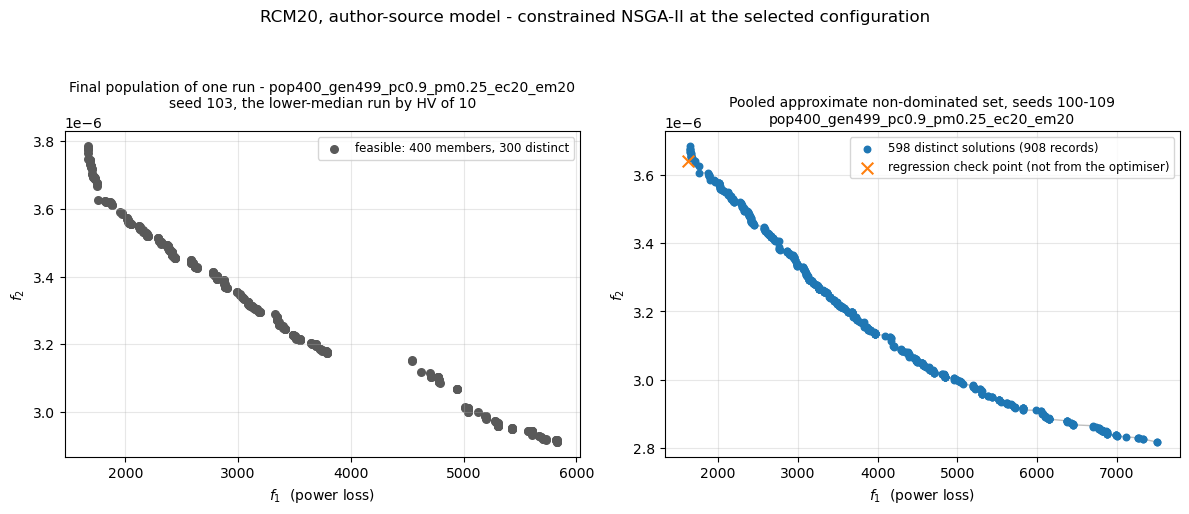

left panel: seed 103: the lower-median run by HV among the 10 held-out runs that found feasible points (HV 0.836; range 0.663-0.886)


In [37]:
def save_show(fig, name):
    path = FIGURE_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    return path


if HAVE_FRONT:
    ranked = sorted((r for r in confirm_best if r["status"] == "ok" and r["feasible_count"] > 0),
                    key=lambda r: (normalised_hv(r, BOX), r["seed"]))
    representative = ranked[(len(ranked) - 1) // 2]          # lower median by HV
    REPRESENTATIVE_NOTE = (f"seed {representative['seed']}: the lower-median run by HV among the "
                           f"{len(ranked)} held-out runs that found feasible points "
                           f"(HV {normalised_hv(representative, BOX):.3f}; range "
                           f"{normalised_hv(ranked[0], BOX):.3f}-{normalised_hv(ranked[-1], BOX):.3f})")
    rep_f = np.asarray(representative["final_f"], dtype=float)
    rep_cv = np.asarray(representative["final_cv"], dtype=float)
    rep_feasible = rep_cv <= BEST_CONFIG["cv_tol"]
    rep_records, rep_distinct = nd_counts(representative)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
    ax = axes[0]
    if (~rep_feasible).any():
        ax.scatter(rep_f[~rep_feasible, 0], rep_f[~rep_feasible, 1], s=26, facecolors="none",
                   edgecolors="tab:red", linewidths=0.9, label=f"infeasible ({int((~rep_feasible).sum())})")
    ax.scatter(rep_f[rep_feasible, 0], rep_f[rep_feasible, 1], s=30, color="0.35",
               label=f"feasible: {int(rep_feasible.sum())} members, "
                     f"{len(np.unique(rep_f[rep_feasible], axis=0))} distinct")
    ax.set_title(f"Final population of one run - {representative['label']}\n"
                 f"seed {representative['seed']}, the lower-median run by HV of {len(ranked)}",
                 fontsize=10)
    ax.set_xlabel("$f_1$  (power loss)"); ax.set_ylabel("$f_2$")
    ax.legend(loc="upper right", fontsize=8.5); ax.grid(alpha=0.3)

    ax = axes[1]
    ax.plot(FINAL_FRONT_F[:, 0], FINAL_FRONT_F[:, 1], "-", color="0.75", linewidth=1, zorder=1)
    ax.scatter(FINAL_FRONT_F[:, 0], FINAL_FRONT_F[:, 1], s=22, color="tab:blue", zorder=2,
               label=f"{len(FINAL_FRONT_F)} distinct solutions ({FINAL_RECORDS} records)")
    ax.scatter([REGRESSION_F[0]], [REGRESSION_F[1]], marker="x", s=70, color="tab:orange", zorder=3,
               label="regression check point (not from the optimiser)")
    ax.set_title(f"Pooled approximate non-dominated set, seeds {FINAL_SEEDS[0]}-{FINAL_SEEDS[-1]}\n"
                 f"{BEST_ROW['label']}", fontsize=10)
    ax.set_xlabel("$f_1$  (power loss)"); ax.set_ylabel("$f_2$")
    ax.legend(loc="upper right", fontsize=8.5); ax.grid(alpha=0.3)
    fig.suptitle("RCM20, author-source model - constrained NSGA-II at the selected configuration")
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    FIG_FRONT = save_show(fig, "author_final_front.png")
    print(f"left panel: {REPRESENTATIVE_NOTE}")
else:
    REPRESENTATIVE_NOTE = None

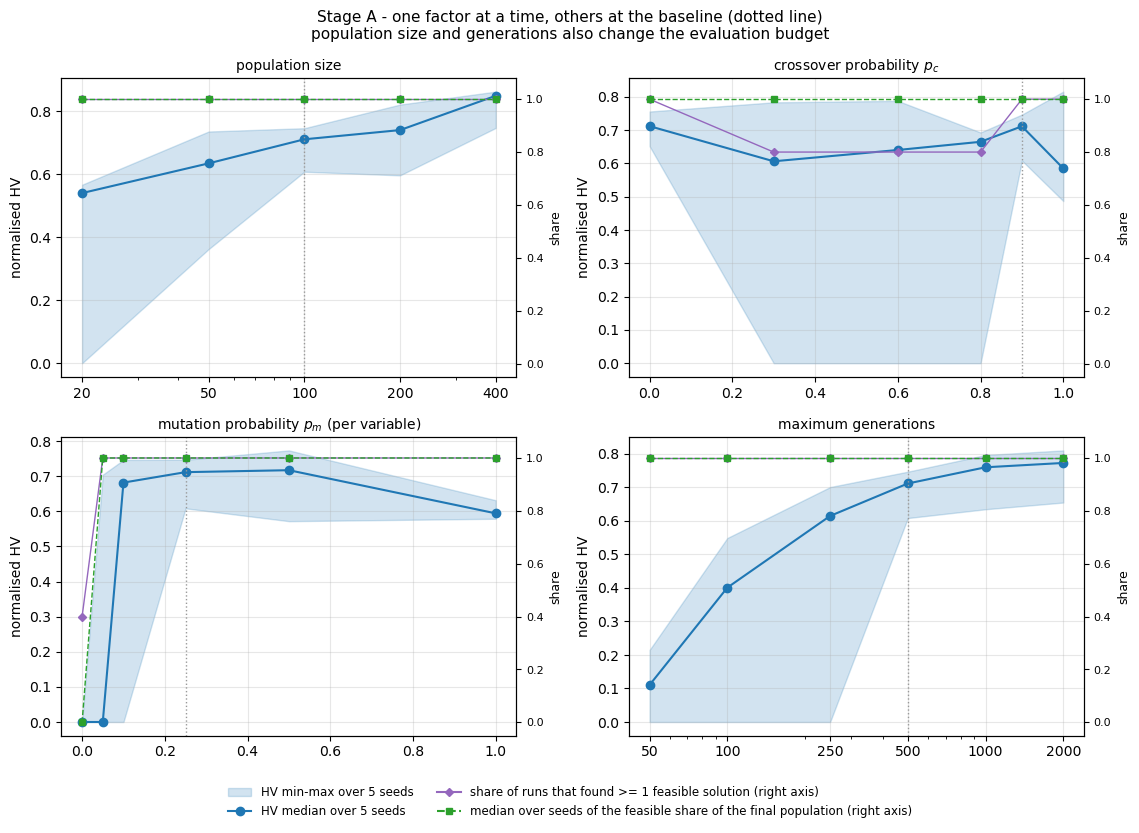

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.8))
sweeps = (("population size", "pop_size", POP_LEVELS, axes[0, 0], True),
          ("crossover probability $p_c$", "pc", PC_LEVELS, axes[0, 1], False),
          ("mutation probability $p_m$ (per variable)", "pm", PM_LEVELS, axes[1, 0], False),
          ("maximum generations", "max_gen", GEN_LEVELS, axes[1, 1], True))
for title, key, levels, ax, logx in sweeps:
    medians, lows, highs, feas, found = [], [], [], [], []
    for level in levels:
        label = config_label(dict(BASELINE, **{key: level}))
        runs = [r for r in stage_a if r["label"] == label and r["status"] == "ok"]
        hv = np.array([normalised_hv(r, BOX) for r in runs])
        medians.append(np.median(hv)); lows.append(hv.min()); highs.append(hv.max())
        feas.append(np.median([r["feasible_ratio"] for r in runs]))
        found.append(np.mean([r["feasible_count"] > 0 for r in runs]))
    ax.fill_between(levels, lows, highs, alpha=0.2, color="tab:blue")
    ax.plot(levels, medians, "o-", color="tab:blue")
    ax.axvline(BASELINE[key], color="0.6", linestyle=":", linewidth=1)
    twin = ax.twinx()
    twin.plot(levels, found, "D-", color="tab:purple", markersize=4, linewidth=1)
    twin.plot(levels, feas, "s--", color="tab:green", markersize=4, linewidth=1)
    twin.set_ylim(-0.05, 1.08)
    twin.set_ylabel("share", fontsize=9)
    twin.tick_params(axis="y", labelsize=8)
    if logx:
        ax.set_xscale("log")
        ax.set_xticks(levels); ax.set_xticklabels([str(v) for v in levels])
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("normalised HV")
    ax.grid(alpha=0.3)
handles = [plt.Rectangle((0, 0), 1, 1, color="tab:blue", alpha=0.2),
           plt.Line2D([], [], color="tab:blue", marker="o"),
           plt.Line2D([], [], color="tab:purple", marker="D", markersize=4),
           plt.Line2D([], [], color="tab:green", marker="s", linestyle="--", markersize=4)]
labels = [f"HV min-max over {len(SEEDS)} seeds", f"HV median over {len(SEEDS)} seeds",
          "share of runs that found >= 1 feasible solution (right axis)",
          "median over seeds of the feasible share of the final population (right axis)"]
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False,
           bbox_to_anchor=(0.5, -0.07), fontsize=8.5)
fig.suptitle("Stage A - one factor at a time, others at the baseline (dotted line)\n"
             "population size and generations also change the evaluation budget", fontsize=11)
fig.tight_layout()
FIG_PARAMS = save_show(fig, "author_parameter_effects.png")

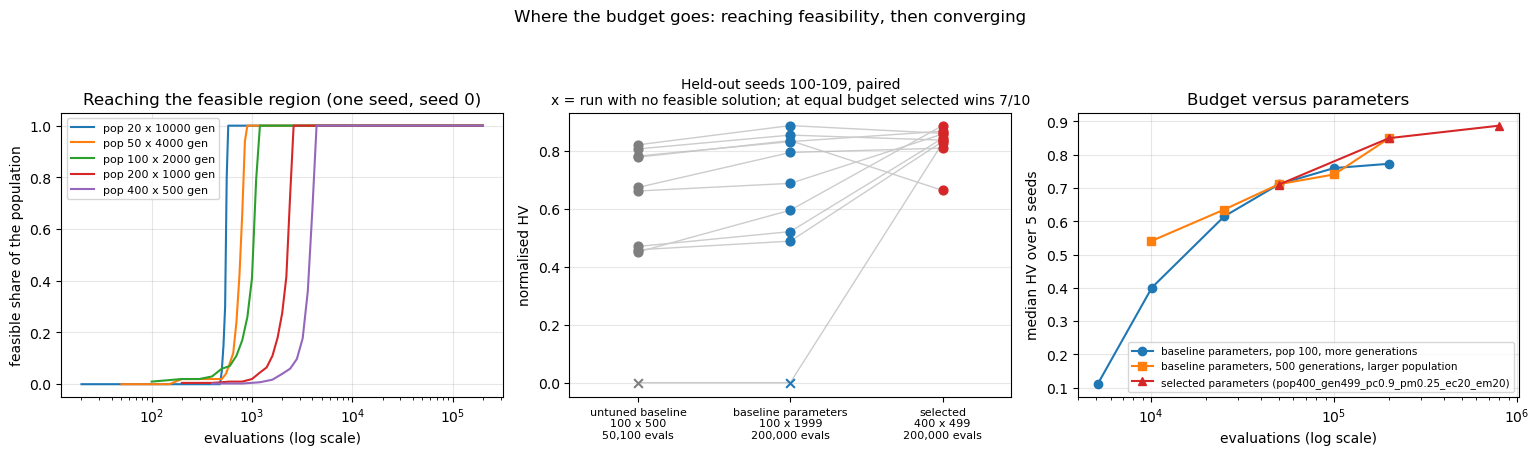

In [39]:
def hv_curve(labels_and_evals, records):
    xs, ys = [], []
    for label, evals in labels_and_evals:
        runs = [r for r in records if r["label"] == label and r["status"] == "ok"]
        if runs:
            xs.append(evals)
            ys.append(float(np.median([normalised_hv(r, BOX) for r in runs])))
    return xs, ys


fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6))
ax = axes[0]
for pop, gen in BUDGET_SPLITS:
    history = [r for r in stage_b
               if r["label"] == config_label(dict(BASELINE, pop_size=pop, max_gen=gen))
               and r["status"] == "ok"][0]["history"]
    ax.plot(np.maximum(history["n_evals"], 1), history["feasible_ratio"],
            label=f"pop {pop} x {gen} gen")
ax.set_xscale("log")
ax.set_xlabel("evaluations (log scale)"); ax.set_ylabel("feasible share of the population")
ax.set_title(f"Reaching the feasible region (one seed, seed {SEEDS[0]})")
ax.legend(fontsize=8); ax.grid(alpha=0.3)

ax = axes[1]
arms = ((f"untuned baseline\n{BASELINE['pop_size']} x {BASELINE['max_gen']}\n"
         f"{BASELINE['pop_size'] * (BASELINE['max_gen'] + 1):,} evals", confirm_base, "tab:gray"),
        (f"baseline parameters\n{MATCHED_BASELINE['pop_size']} x {MATCHED_BASELINE['max_gen']}\n"
         f"{BUDGET:,} evals", confirm_matched, "tab:blue"),
        (f"selected\n{BEST_CONFIG['pop_size']} x {BEST_CONFIG['max_gen']}\n"
         f"{BUDGET:,} evals", confirm_best, "tab:red"))
by_arm = [{r["seed"]: r for r in records} for _, records, _ in arms]
for seed in shared:
    ax.plot(range(len(arms)), [normalised_hv(arm[seed], BOX) for arm in by_arm], "-",
            color="0.8", linewidth=1, zorder=1)
for position, ((_, _, colour), arm) in enumerate(zip(arms, by_arm)):
    for seed in shared:
        record = arm[seed]
        category = run_category(record, BOX)
        marker = {"no feasible solution": "x", "feasible, HV = 0": "o"}.get(category, "o")
        face = "none" if category == "feasible, HV = 0" else colour
        ax.scatter([position], [normalised_hv(record, BOX)], s=40, marker=marker,
                   color=colour, facecolors=face, zorder=2)
ax.set_xticks(range(len(arms)))
ax.set_xticklabels([name for name, _, _ in arms], fontsize=8)
ax.set_xlim(-0.45, len(arms) - 0.55)
ax.set_ylim(bottom=-0.05)
ax.set_ylabel("normalised HV")
ax.set_title(f"Held-out seeds {FINAL_SEEDS[0]}-{FINAL_SEEDS[-1]}, paired\n"
             f"x = run with no feasible solution; at equal budget selected wins "
             f"{wins_matched}/{len(shared)}", fontsize=10)
ax.grid(alpha=0.3, axis="y")

ax = axes[2]
xs, ys = hv_curve([(config_label(dict(BASELINE, max_gen=g)), BASELINE["pop_size"] * (g + 1))
                   for g in GEN_LEVELS], stage_a)
ax.plot(xs, ys, "o-", label=f"baseline parameters, pop {BASELINE['pop_size']}, more generations")
xs, ys = hv_curve([(config_label(dict(BASELINE, pop_size=p)), p * (BASELINE["max_gen"] + 1))
                   for p in POP_LEVELS], stage_a)
ax.plot(xs, ys, "s-", label=f"baseline parameters, {BASELINE['max_gen']} generations, larger population")
xs, ys = hv_curve([(row["label"], row["evals"]) for row in budget_rows], budget_runs)
ax.plot(xs, ys, "^-", color="tab:red", label=f"selected parameters ({BEST_ROW['label']})")
ax.set_xscale("log")
ax.set_xlabel("evaluations (log scale)"); ax.set_ylabel(f"median HV over {len(SEEDS)} seeds")
ax.set_title("Budget versus parameters")
ax.legend(fontsize=7.5, loc="lower right"); ax.grid(alpha=0.3)
fig.suptitle("Where the budget goes: reaching feasibility, then converging")
fig.tight_layout(rect=(0, 0, 1, 0.93))
FIG_BUDGET = save_show(fig, "author_budget_split.png")

In [40]:
def x_fingerprint(record):
    """sha256 of the final population's decision variables, to compare runs exactly."""
    return hashlib.sha256(np.ascontiguousarray(record["final_x"], dtype=np.float64).tobytes()).hexdigest()


per_run = [dict(label=r["label"], seed=r["seed"], n_evals=r["n_evals"],
                feasible_count=r["feasible_count"], min_cv=r["min_cv"],
                f1_min=r["f1_min"], f2_min=r["f2_min"], hv=normalised_hv(r, BOX),
                nd_records=nd_counts(r)[0], nd_distinct=nd_counts(r)[1],
                final_x_sha256=x_fingerprint(r))
           for r in DISTINCT_RUNS]
SUMMARY = dict(
    baseline=BASELINE, seeds=list(SEEDS), final_seeds=list(FINAL_SEEDS), budget=BUDGET,
    normalisation_box=BOX, hv_reference=[1.1, 1.1], feasibility_tolerance=BASELINE["cv_tol"],
    best_config=BEST_CONFIG, best_label=BEST_ROW["label"],
    stage_a=stage_a_rows, stage_b=stage_b_rows, stage_c=stage_c_rows, pc_cells=PC_CELLS,
    budget_scaling=budget_rows, confirmation=confirm_rows,
    confirmation_wins=dict(vs_matched_baseline=int(wins_matched),
                           vs_untuned_baseline=int(wins_untuned), n_seeds=len(shared)),
    outcomes={k: len(v) for k, v in categories.items()},
    final_front=dict(records=FINAL_RECORDS, distinct=len(FINAL_FRONT_F),
                     f=FINAL_FRONT_F.tolist(), x=FINAL_FRONT_X.tolist()),
    runs=per_run,
)
(RESULT_DIR / "rcm20_summary.json").write_text(json.dumps(SUMMARY, indent=1, default=float))
print(f"wrote {RESULT_DIR / 'rcm20_summary.json'} ({len(per_run)} runs)")

wrote results/rcm20_summary.json (195 runs)


## 4.5 Discussion

**Mutation probability** had the clearest effect. With `pm = 0`, three of five
runs ended without a feasible solution and the other two had HV = 0; with
`pm = 0.05` all runs were feasible but four of five had HV = 0. For `pm` from 0.1
to 0.5 the median HV was 0.68-0.72, and `pm = 1` reduced each run to about 14
distinct solutions. This may be because without mutation the search can only
recombine existing parents, while `pm = 1` perturbs every variable of every
child.

**Crossover probability** showed no clear trend in Stage A (medians
0.585-0.712), and `pc = 0.3, 0.6, 0.8` each had one seed without a feasible
solution. In Stage C, raising `pc` from 0 to 0.9 changed the median HV by between
-0.041 and +0.108 depending on `N` and `pm`, so its effect depends on the other
settings; five seeds are not enough to rank the `pc` levels.

**Population size and generations** both raised HV in Stage A, but they also
added evaluations. At approximately 200,000 evaluations (Stage B) the five
splits gave median HV 0.760-0.850 with overlapping ranges. The number of
distinct solutions grew with `N` (median 18 at `N = 20`, 249 at `N = 400`). The
`G` sweep follows the same runs to different stopping points and shows HV rising
quickly up to about `G = 500` (0.711) and slowly afterwards (0.773 at
`G = 2000`).

**Selected configuration.** The rule in Stage C selected `N = 400, G = 499,
pc = 0.9, pm = 0.25` at 200,000 evaluations; only `N` (and hence `G`) differs
from the baseline. On seeds 100-109 at the same budget it had a higher HV than
the baseline parameters with `N = 100, G = 1999` on 7 of 10 seeds (median 0.839
vs 0.740) and more distinct solutions (median 261.5 vs 86.0), but a larger
largest gap (0.136 vs 0.051) and a higher median run-minimum `f1` (1657.75 vs
1634.35). In the additional budget runs (seeds 0-4) its median HV was 0.710,
0.850 and 0.887 at 50,000, 200,000 and 800,000 evaluations; these runs were not
part of the selection.

**Final solutions and limitations.** The ten confirmation runs gave 908
non-dominated records, i.e. 598 distinct approximate non-dominated solutions,
all feasible under the raw formulas. Most lie close to the load, pressure and
temperature limits (relative slack below 1% for 99%, 100% and 96% of them); this
describes the solutions found, not a proven property of the Pareto set. The
known feasible point `f = (1621.31, 3.64051e-6)`, which was never inserted into
any population, dominates the lowest-`f1` reported solution
`(1646.06, 3.68457e-6)`, so that end of the set is not fully converged. Nine of
195 runs found no feasible solution, each setting used five seeds, interactions
were tested only in Stage C, and `eta_c`, `eta_m` were fixed at 20.